# How much economic value do meta-labeling and bet sizing add to the four primary strategies?

**Question.** For the four primary strategies of `quant_forge.strategies` (RSI cross-above, Donchian breakout continuation,
TIS momentum confluence, SuperTrend regime confluence), with their default entry and exit rules, 4-hour Binance spot bars,
40 assets and 5 bps per fill: how much do (a) a meta-model that predicts whether a signalled trade will close at a profit
after costs and (b) López de Prado's probability-based bet sizing add, in money terms, over taking every signal with the
same size, and over the simplest alternative that needs no model, inverse-volatility sizing?

**Design in one paragraph.** The primary strategy fixes the direction and the exit; the meta-label is `y = 1[trade_return > 0]`
net of fees (AFML §3.6). For every strategy and every outer walk-forward window the meta-model is trained **only on the 20
original assets** (`SEEN`) and predicts the window's trades on those assets and, separately, on 20 assets it has never seen
(`NEW`) — the cross-asset transfer experiment of the earlier notebooks. Everything that is learned — fractional-differentiation
order, feature clusters and their importance, feature selection, PCA, hyperparameters, probability calibration, the filter
threshold, the break-even win rate, every percentile rank and every normalisation constant used by a sizing rule — is fitted on
the training trades of the window with a purged, embargoed K-fold on common calendar folds (AFML ch. 7), so that every sizing
input exists at the moment the trade is placed. Trading value is measured on the outer predictions only, with the same costs,
the same capital budget and the same underlying signals for all sizing rules, with monthly block-bootstrap and permutation
uncertainty.

**Sources used for the methodological choices** (cited inline as AFML = *Advances in Financial Machine Learning*, 2018;
MLAM = *Machine Learning for Asset Managers*, 2020; Joubert = *Meta-Labeling: Theory and Framework*, J. Financial Data
Science 2022; mlfinpy = the `mlfinpy` package documentation, version printed below):

| Choice | Source |
|---|---|
| meta-label on the primary trade's own exit | AFML §3.6 (meta-labeling); Joubert §2 (primary / secondary model) |
| fractional differentiation with fixed-width window, order chosen by ADF | AFML §5.4–5.6, Snippets 5.3–5.4; `mlfinpy.util.frac_diff` |
| clustering of features before importance | MLAM §4.4 (ONC, Snippets 4.1–4.2); MLAM §6.5 (clustered MDI / MDA) |
| MDI, MDA, placebo features, PCA eigen-rank check | AFML §8.3–8.4, Snippets 8.2–8.3, 8.5–8.6 |
| purged K-fold with embargo on calendar folds | AFML §7.4, Snippets 7.1–7.3; `quant_forge.validation.PurgedKFold` (single-asset version) |
| hyperparameter search with purged CV and log-loss scoring | AFML §9.2–9.4 |
| bet size from predicted probability, discretisation | AFML §10.3, 10.5, Snippet 10.1; asymmetric payouts: AFML §15.2–15.3 |
| decomposition of the value of meta-labeling into filtering and sizing | Joubert §3–4 |
| inverse-volatility sizing as the model-free benchmark | earlier notebooks `meta_labeling_beating_the_prior`, `meta_labeling_sizing_vs_prior` |

**This version is implemented with `quant_forge` calls.** It reproduces `meta_labeling_economic_value.ipynb` (same data,
features, trades, walk-forward fits and tables; model probabilities agree to ~1e-12, the rounding noise of multi-threaded
forests); everything that notebook implemented from scratch now lives in reusable packages (table below; usage in
`docs/`). Walk-forward results are cached under `~/.cache/quantforge/meta_econ_qf/` keyed by a hash of the configuration,
the data and the library version; delete that folder to recompute everything.

### Where each step lives in `quant_forge`

| Step | Library call |
|---|---|
| 4h Binance klines, local parquet cache, bar frame | `quant_forge.data.load_binance_bars`, `SEEN_ASSETS`, `NEW_ASSETS`, `TICK_SIZES` |
| bar features V, T, F, CAL (per asset) and M, R, X (panel) | `quant_forge.features.bar_features` |
| fractional differentiation, ADF order choice | `features.select_ffd_order`, `add_ffd_features`, `adf_statistic`, `ffd_weights` |
| strategies on 40 assets, closed trades + decision-time features | `quant_forge.metalabeling.build_trade_panel` (uses `quant_forge.strategies`) |
| track record `S`, side orientation, families, candidates | `metalabeling.prepare_meta_dataset`, `features.track_record_features`, `orient_by_side` |
| purged K-fold on calendar folds for a panel, walk-forward windows | `quant_forge.validation.CalendarPurgedKFold`, `calendar_windows` |
| redundancy / ONC clusters, placebos, clustered MDA / MDI, selection, PCA check | `quant_forge.feature_selection` |
| LR / RF / HGB specs, purged tuning by log loss, Platt calibration | `quant_forge.models` |
| per-window worker, parallel cached walk-forward | `metalabeling.fit_window`, `run_walk_forward`, `collect_predictions` |
| AFML bet sizing, rule set, training constants, capital budget | `quant_forge.sizing` |
| Δ log loss, AUC, IC, reliability; Sharpe, bootstrap, permutation, exposure | `quant_forge.evaluation` |
| run reports | `metalabeling.window_summary`, `feature_selection_records`, `family_selection_table`, `sizing_constants_table` |

## 0. What has already been examined (and is therefore not clean evidence)

| Assets | Period | Used by | Status |
|---|---|---|---|
| `SEEN` (20) | A: decided before 2021-09-01 | `meta_labeling_beating_the_prior` (frozen test + ~9 post-hoc configs), `meta_labeling_sizing_vs_prior` | seen several times |
| `SEEN` (20) | B: 2021-09-01 → 2026-08-31 | `cross_asset_transfer_meta_labeling`, multi-config grid, feature-engineering notebook, both sizing notebooks | development period, seen many times |
| `NEW` (20) | A and B | `meta_labeling_sizing_vs_prior` (one frozen run of 4 hypotheses + a post-hoc volatility/trend section) | seen once |
| all 40 | C: decided on/after 2026-09-01 | reported in the two sizing notebooks, never used for a decision | fresh but short (~2.5 months) |

Consequences for reading the results: the transfer experiment on `NEW` assets is clean with respect to **model fitting** (the
model never trains on them) but the *design* of this notebook was informed by what was learned on them once. The honest
ordering of evidence is: `NEW` assets < `SEEN` assets in A < `SEEN` assets in B; period C cannot decide anything yet. Known
facts that shape expectations: no feature set beat the strategy's win-rate prior in log loss; rank sizing by a meta-model beat
uniform sizing on `NEW` assets (+0.12 Sharpe) but a one-variable volatility model did as well; inverse-volatility sizing was the
only effect that survived every test.

## 1. Configuration

In [1]:
import os, sys, time, warnings, importlib.metadata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from IPython.display import display


def find_project_root():
    for path in [Path.cwd(), *Path.cwd().parents]:
        if (path / "quant_forge/strategies").exists():
            return path
    raise FileNotFoundError("QuantForge project root not found")


ROOT = find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))          # the repository's quant_forge (also inherited by joblib worker processes)

import quant_forge
import quant_forge.strategies as qs
from quant_forge import data as qd, features as qf, metalabeling as ml, evaluation as qe, sizing as qz
from quant_forge import feature_selection as fs, models as qm
from quant_forge.validation import CalendarPurgedKFold, PurgedKFold, calendar_windows
from quant_forge.utils import DEFAULT_CACHE_ROOT, DiskCache, frame_fingerprint

SEEN, NEW = qd.SEEN_ASSETS, qd.NEW_ASSETS
ALL_ASSETS = SEEN + NEW
DATA_END = pd.Timestamp("2026-11-19 00:00", tz="UTC")
WARMUP_DAYS = 30
BPD = 6                                   # bars per day (4h bars)
FEE_BPS, NOTIONAL = 5.0, 10_000.0
A_END, B_END = pd.Timestamp("2021-09-01", tz="UTC"), pd.Timestamp("2026-09-01", tz="UTC")

# outer walk-forward: 12-month windows from 2019-03-01, the last one ends at DATA_END
WINDOWS = calendar_windows("2019-03-01", end=DATA_END, years=1)

# fractional differentiation (AFML ch. 5): d chosen on bars before the first outer window
FFD_GRID = [round(0.1 * i, 1) for i in range(0, 11)]
FFD_THRESH = 1e-4
FFD_TRAIN_END = WINDOWS[0][0]

# everything learned inside a window (defaults of MetaLabelingConfig = this study): MIN_TRAIN 200, coverage 0.70,
# 4 calendar folds, embargo 1 %, redundancy clusters at 1 - |rho| <= 0.3, 5 placebos, 3 permutations, LR/RF/HGB (+LR-PCA).
# cover_all_events=False keeps the fold edges of the original notebook (see section 6) so that its numbers are reproduced.
SEED = 0
CONFIG = ml.MetaLabelingConfig(train_assets=tuple(SEEN), seed=SEED, cover_all_events=False)
ONC_MAX_CLUSTERS, ONC_N_INIT = 30, 5       # ONC (MLAM 4.4), diagnostic only

# sizing / economics
SIZE_CAP = 10.0                           # position limit: no trade larger than 10 x NOTIONAL after normalisation
N_BOOT, N_PERM_TEST = 2000, 500

S = qs.Strategies
STRATEGIES = {S.RSI_CROSS_ABOVE: "RSI", S.DONCHIAN_BREAKOUT_CONTINUATION: "DONCHIAN",
              S.TIS_BTC_MOMENTUM_CONFLUENCE: "TIS", S.SUPERTREND_REGIME_CONFLUENCE: "SUPERTREND"}
SS = list(STRATEGIES.values())

CPUS = os.cpu_count() or 1
N_JOBS = min(8, CPUS)                     # processes for assets / walk-forward pairs
WF_THREADS = max(1, CPUS // N_JOBS)       # forest threads inside each walk-forward process
pd.set_option("display.width", 230)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 200)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
T0 = time.time()
print("quant_forge", quant_forge.__version__, "from", Path(quant_forge.__file__).parent, "| pandas", pd.__version__,
      "| sklearn", importlib.metadata.version("scikit-learn"), "| cpus", CPUS)

quant_forge 0.2.0 from /home/octa/Desktop/QuantForge/quant_forge | pandas 2.3.3 | sklearn 1.7.2 | cpus 22


## 2. Data: 4h Binance spot bars for 40 assets

Bars come from the public klines endpoint (`quant_forge.data.load_binance_bars`, which only downloads what
the local parquet cache is missing) (verified identical to the `cryptods` 4h time bars in
`../meta_labeling_beating_the_prior.ipynb`), cached locally, fixed `DATA_END`. The first 30 days after listing are dropped;
`bar_seq` comes from the 4h grid so data gaps split indicator segments inside the strategy library.

In [2]:
t = time.time()
bars = qd.load_binance_bars(ALL_ASSETS, end=DATA_END, interval="4h", warmup_days=WARMUP_DAYS)
summary = pd.DataFrame({"group": {a: "SEEN" if a in SEEN else "NEW" for a in ALL_ASSETS},
                        "first bar": {a: b.index.min().date() for a, b in bars.items()},
                        "bars": {a: len(b) for a, b in bars.items()}})
print(f"{len(bars)} assets, {sum(map(len, bars.values())):,} bars, last bar end {max(b.index.max() for b in bars.values())} "
      f"({time.time() - t:.1f} s)")
summary.T

40 assets, 635,908 bars, last bar end 2026-11-19 00:00:00+00:00 (0.3 s)


,BTC,ETH,BNB,SOL,XRP,ADA,AVAX,BCH,DOGE,DOT,LINK,LTC,UNI,AAVE,ATOM,ETC,FIL,NEAR,TRX,XLM,ALGO,VET,THETA,SAND,MANA,AXS,ICP,HBAR,CRV,GRT,ENJ,CHZ,ZEC,DASH,XTZ,COMP,SNX,IOTA,ZIL,QTUM
group,SEEN,SEEN,SEEN,SEEN,SEEN,SEEN,SEEN,SEEN,SEEN,SEEN,SEEN,SEEN,SEEN,SEEN,SEEN,SEEN,SEEN,SEEN,SEEN,SEEN,NEW,NEW,NEW,NEW,NEW,NEW,NEW,NEW,NEW,NEW,NEW,NEW,NEW,NEW,NEW,NEW,NEW,NEW,NEW,NEW
first bar,2017-09-16,2017-09-16,2017-12-06,2020-09-10,2018-06-03,2018-05-17,2020-10-22,2019-12-28,2019-08-04,2020-09-18,2019-02-15,2018-01-12,2020-10-17,2020-11-14,2019-05-29,2018-07-12,2020-11-14,2020-11-13,2018-07-11,2018-06-30,2019-07-22,2018-08-24,2019-05-10,2020-09-13,2020-09-05,2020-12-04,2021-06-10,2019-10-29,2020-09-14,2021-01-17,2019-05-18,2019-10-06,2019-04-20,2019-04-27,2019-10-24,2020-07-25,2020-08-08,2018-06-30,2019-03-21,2018-04-18
bars,20089,20089,19604,13565,18535,18638,13313,15105,15979,13519,16997,19382,13344,13176,16383,18306,13172,13181,18310,18375,16060,18047,16495,13545,13594,13053,11928,15466,13541,12793,16449,15604,16615,16573,15495,13847,13761,18375,16794,18811


## 3. Candidate features available at signal time

All candidate features are computed from bars up to and including the signal bar and are copied from the signal bar by the
strategy library (`context_columns`), so by construction nothing after the decision enters. Families:

| Family | Content | Count |
|---|---|---|
| `LIB` | the strategy's own indicator features (price-level ones expressed relative to the signal close) | 1–12 per strategy |
| `RAW` | raw bar levels: `open`, `close`, `volume`, `quote_volume`, `n_trades` (kept to *show* why levels are unusable) | 5 |
| `FFD` | fractionally differentiated log open / close / volume (order chosen in §4), raw and trailing-standardised per asset | 6 |
| `V` | own volatility: realised vol 1d…90d, ratios, 1-year percentile, Parkinson and Garman-Klass (via `mlfinpy.util.volatility`), Bollinger width, ATR/price, bar range | 17 |
| `T` | own trend: vol-scaled and raw log returns 1d…90d, EMA/SMA distances, drawdown / run-up, efficiency ratios, RSI 7/14/28, position in range, return skew/kurtosis/autocorrelation | 38 |
| `F` | flow / activity: taker imbalance 1…42 bars, relative quote volume, relative trade count, Amihud illiquidity, volume-return correlation | 12 |
| `CAL` | calendar: hour of day and day of week (sine/cosine), weekend | 5 |
| `M` | market state from the equal-weighted index of the assets with data at *t*: returns, volatility, percentile, drawdown, breadth, dispersion, alt-vs-BTC, average correlation, BTC's own trend/vol | 23 |
| `R` | relative strength vs the market median, beta, correlation with the market | 6 |
| `X` | cross-sectional percentile ranks at *t* of selected `V`/`T`/`F` features among the assets with data | 21 |
| `S` | track record: trailing win rates and mean returns of the same strategy (all assets / same asset), open positions, signals in 24h, all from trades **closed strictly before** the decision | 10 |

Direction-carrying features are multiplied by `side` (SuperTrend also trades short). Price-level inputs are addressed in §4.

`quant_forge.features.bar_features` computes every bar-level family in one call (column definitions in its module
docstrings and in `../../../docs/features.md`); a test in `tests/features` checks that truncating the data after *t* leaves every
feature at *t* unchanged.

In [3]:
t = time.time()
feats, mkt = qf.bar_features(bars, bars_per_day=BPD, btc="BTC", return_market=True)
print(f"bar-level features: {time.time() - t:.0f} s; {len(qf.model_columns(feats['BTC']))} columns per asset "
      f"(+ {len(qf.AUX_COLUMNS)} auxiliary); market state: {mkt.shape[1]} columns")

bar-level features: 10 s; 125 columns per asset (+ 6 auxiliary); market state: 26 columns


## 4. Stationarity of price levels and fractional differentiation

Raw price and volume levels (`open`, `close`, `volume`, and the library's own level features such as `dc_high`, `ema_trend`,
`st_band`) are non-stationary: a model trained on 2019 levels has no idea what a 2024 level means, and levels differ by orders of
magnitude across assets, so they cannot be pooled. AFML ch. 5 proposes to difference the series only as much as needed to pass a
unit-root test, keeping as much memory as possible: the fixed-width-window fractional differentiation (FFD, §5.5, Snippet 5.3)
with the smallest order *d* whose ADF statistic rejects the unit root (§5.6, Snippet 5.4).

Implementation. `quant_forge.features.ffd_weights` reproduces `mlfinpy.util.frac_diff.get_weights_ffd` exactly (tested) and
`frac_diff_ffd` applies the weights causally with a convolution; the cell checks numerically that this equals
`mlfinpy.util.frac_diff.frac_diff_ffd` when mlfinpy is installed (mlfinpy loops in Python and is too slow for 40 × 20 000 bars ×
11 orders). `select_ffd_order` runs the per-asset ADF search and returns the trade-off table. The weight threshold is `1e-4` (AFML uses `1e-5` on daily data; on 4h bars
`1e-4` keeps the window below ~1 000 bars, see the usable-history column). The order is chosen **per asset on bars before the first
outer window (2019-03-01)**: the smallest grid *d* whose ADF statistic (constant, one lag, as in Snippet 5.4) is below the 5 %
critical value. For assets listed after that date, the order is the median of the orders found on the earlier-listed assets, so no
later data influences the choice. A single pooled order `D_STAR` (the 90th percentile of the per-asset orders, i.e. stationary for
at least 90 % of the assets) is used for the model feature, because one pooled model needs one definition of the feature.

Because an FFD series with *d* < 1 keeps a slowly moving level component, its scale still differs across assets. Two versions are
therefore offered: the raw FFD value (asset-specific scale) and a **trailing per-asset standardisation** (z-score against the
trailing 365-day mean and standard deviation, which is available at signal time).

FFD check vs mlfinpy.frac_diff_ffd (d=0.4, 600 bars, window 282): max |diff| = 0.00e+00
assets with >= 200 pre-2019-03 bars: 12; per-asset d*: {0.0: 1, 0.1: 1, 0.2: 34, 0.3: 4}; fallback for later listings 0.2; pooled D_STAR = 0.3


,share_rejecting,median_adf,median_corr,window_bars,window_days,crit5
d,,,,,,
0.0,0.083,-1.399,1.000,1,0.167,-2.863
0.1,0.083,-2.123,0.985,503,83.833,-2.864
0.2,0.667,-3.246,0.929,497,82.833,-2.864
0.3,1.000,-4.954,0.835,388,64.667,-2.864
0.4,1.000,-7.502,0.729,282,47.000,-2.864
0.5,1.000,-10.733,0.589,200,33.333,-2.864
0.6,1.000,-13.979,0.426,140,23.333,-2.863
0.7,1.000,-17.637,0.299,97,16.167,-2.863
0.8,1.000,-21.200,0.198,64,10.667,-2.863


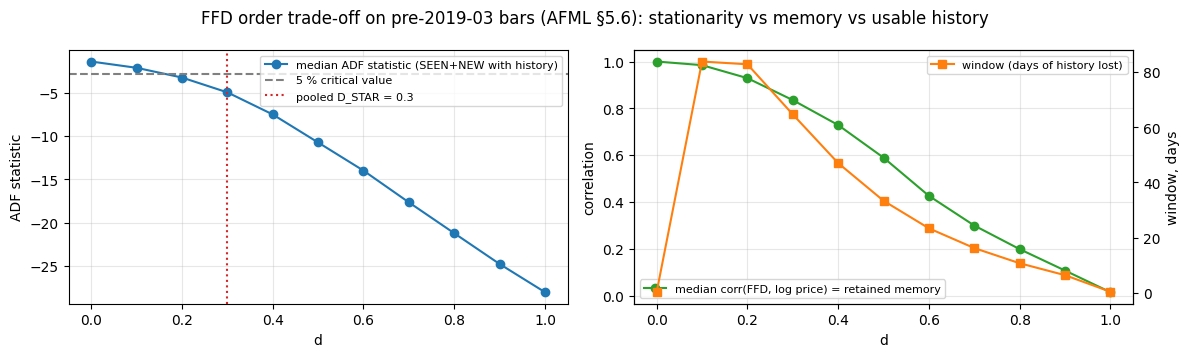

In [4]:
try:   # numerical check against mlfinpy's own implementation on a short series (optional dependency)
    from mlfinpy.util.frac_diff import frac_diff_ffd as mlfinpy_ffd
    _s = feats["BTC"]["_log_close"].iloc[:600]
    _ref = mlfinpy_ffd(_s.to_frame("x"), 0.4, FFD_THRESH)["x"]
    _mine, _w = qf.frac_diff_ffd(_s.to_numpy(), 0.4, FFD_THRESH)
    _ok = np.nanmax(np.abs(_ref.to_numpy() - _mine))
    print(f"FFD check vs mlfinpy.frac_diff_ffd (d=0.4, 600 bars, window {_w}): max |diff| = {_ok:.2e}")
    assert _ok < 1e-9
except ImportError:
    print("mlfinpy not installed: FFD check skipped (quant_forge.features.ffd_weights is tested against it in tests/features)")

sel_ffd = qf.select_ffd_order({a: f["_log_close"] for a, f in feats.items()}, train_end=FFD_TRAIN_END, grid=FFD_GRID,
                              thresh=FFD_THRESH, bars_per_day=BPD)
D_STAR, d_star, has_hist, tradeoff = sel_ffd.pooled, sel_ffd.per_asset, sel_ffd.has_history, sel_ffd.tradeoff
print(f"assets with >= 200 pre-2019-03 bars: {int(has_hist.sum())}; per-asset d*: "
      f"{pd.Series(d_star).value_counts().sort_index().to_dict()}; fallback for later listings {sel_ffd.fallback}; pooled D_STAR = {D_STAR}")
display(tradeoff.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(tradeoff.index, tradeoff["median_adf"], marker="o", label="median ADF statistic (SEEN+NEW with history)")
ax[0].axhline(tradeoff["crit5"].median(), color="gray", ls="--", label="5 % critical value")
ax[0].axvline(D_STAR, color="tab:red", ls=":", label=f"pooled D_STAR = {D_STAR}")
ax[0].set_xlabel("d"); ax[0].set_ylabel("ADF statistic"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
ax[1].plot(tradeoff.index, tradeoff["median_corr"], marker="o", color="tab:green", label="median corr(FFD, log price) = retained memory")
ax[1].set_xlabel("d"); ax[1].set_ylabel("correlation"); ax[1].grid(alpha=0.3)
ax2 = ax[1].twinx(); ax2.plot(tradeoff.index, tradeoff["window_days"], color="tab:orange", marker="s", label="window (days of history lost)")
ax2.set_ylabel("window, days"); ax[1].legend(loc="lower left", fontsize=8); ax2.legend(loc="upper right", fontsize=8)
fig.suptitle("FFD order trade-off on pre-2019-03 bars (AFML §5.6): stationarity vs memory vs usable history")
fig.tight_layout(); plt.show()

In [5]:
# apply the pooled order to log open / close / volume of every asset (+ trailing per-asset standardisation), add raw levels
feats = qf.add_raw_levels(qf.add_ffd_features(feats, D_STAR, thresh=FFD_THRESH, bars_per_day=BPD), bars)

# how non-stationary are the raw levels vs the FFD series, on the same pre-2019-03 span (median over assets with history)
chk = []
for a in has_hist[has_hist].index:
    f = feats[a].loc[feats[a].index < FFD_TRAIN_END]
    for c in ["raw_close", "raw_volume", "_log_close", "ffd_log_close", "ffd_log_close_z", "ffd_log_volume", "t_ret_1d", "v_rvol_30d"]:
        chk.append({"asset": a, "series": c, "adf": qf.adf_statistic(f[c].to_numpy())[0]})
chk = pd.DataFrame(chk).groupby("series")["adf"].agg(["median", "min", "max"]).reindex(
    ["raw_close", "_log_close", "ffd_log_close", "ffd_log_close_z", "raw_volume", "ffd_log_volume", "t_ret_1d", "v_rvol_30d"])
chk["rejects_unit_root (median)"] = chk["median"] < tradeoff["crit5"].median()
print("ADF statistics (constant, 1 lag) on pre-2019-03 bars; 5 % critical value about", round(tradeoff["crit5"].median(), 2))
chk.round(2)

ADF statistics (constant, 1 lag) on pre-2019-03 bars; 5 % critical value about -2.86


,median,min,max,rejects_unit_root (median)
series,,,,
raw_close,-1.72,-2.99,-0.78,False
_log_close,-1.40,-3.43,-0.34,False
ffd_log_close,-4.95,-6.51,-3.84,True
ffd_log_close_z,-5.37,-7.49,-3.50,True
raw_volume,-14.60,-23.43,-8.09,True
ffd_log_volume,-20.22,-33.84,-16.00,True
t_ret_1d,-13.50,-18.33,-11.41,True
v_rvol_30d,-0.95,-2.45,-0.52,False


## 5. Running the strategies on all 40 assets

Default parameters, `fee_bps = 5`, `slippage_ticks = 0`. Each closed trade receives the candidate features of its signal bar, its
group (`SEEN` / `NEW`) and its period by decision date: A (< 2021-09-01), B (2021-09-01 … 2026-08-31), C (≥ 2026-09-01).
The library's own level features are turned into ratios to the signal close (`dc_high` → `dc_high / close − 1`, `atr_value` →
`atr_value / close`, …): the stationary content of a level is its distance to the current price.

`metalabeling.build_trade_panel` runs the strategies (assets in parallel processes) and converts the level features with
`features.relative_levels`.

In [6]:
FEATURE_COLS = qf.model_columns(feats["BTC"])
t = time.time()
trades = ml.build_trade_panel(bars, feats, STRATEGIES, feature_columns=FEATURE_COLS, tick_sizes=qd.TICK_SIZES,
                              fee_bps=FEE_BPS, slippage_ticks=0, n_jobs=N_JOBS)
trades["group"] = ml.assign_groups(trades, {"SEEN": SEEN, "NEW": NEW})
trades["period"] = ml.assign_periods(trades["decision_time"], [("A", A_END), ("B", B_END)], last="C")
trades["month"] = trades["exit_time"].dt.strftime("%Y-%m")
print(f"strategies: {time.time() - t:.0f} s; {len(trades):,} closed trades")
pd.crosstab([trades["group"], trades["strategy"]], trades["period"], margins=True, margins_name="total")

strategies: 7 s; 22,389 closed trades


period               A      B    C  total
group strategy                           
NEW   DONCHIAN     465   1072   50   1587
      RSI         1286   2944  119   4349
      SUPERTREND   691   2202   82   2975
      TIS          370    950   41   1361
SEEN  DONCHIAN     637   1186   46   1869
      RSI         1824   3252  119   5195
      SUPERTREND   978   2502  113   3593
      TIS          433    986   41   1460
total             6684  15094  611  22389

In [7]:
# S family (track record from trades closed strictly before the decision), side orientation, families and candidates
ds = ml.prepare_meta_dataset(trades)
trades, FAMILY, CANDIDATES = ds.trades, ds.family, ds.candidates
print(f"candidate features (excluding raw levels and library levels): {len(CANDIDATES)}")
pd.Series({f: sum(1 for c in CANDIDATES if FAMILY[c] == f) for f in qf.FAMILY_ORDER}).to_frame("features").T

candidate features (excluding raw levels and library levels): 168


,LIB,FFD,V,T,F,CAL,M,R,X,S
features,27,6,16,39,12,5,26,6,21,10


In [8]:
N_CAND = {s: len(ds.candidates_for(s)) for s in SS}
hold = trades.groupby("strategy").agg(trades=("y", "size"), win_rate=("y", "mean"), mean_ret_bps=("trade_return", lambda r: 1e4 * r.mean()),
                                      median_hold_h=("holding_hours", "median"), p90_hold_h=("holding_hours", lambda h: h.quantile(0.9)),
                                      avg_win=("trade_return", lambda r: r[r > 0].mean()), avg_loss=("trade_return", lambda r: -r[r <= 0].mean()))
hold["break_even_win_rate"] = hold["avg_loss"] / (hold["avg_win"] + hold["avg_loss"])
hold["candidate features"] = pd.Series(N_CAND)
hold.round(4)

,trades,win_rate,mean_ret_bps,median_hold_h,p90_hold_h,avg_win,avg_loss,break_even_win_rate,candidate features
strategy,,,,,,,,,
DONCHIAN,3456,0.5058,225.8922,80.0,80.0,0.1115,0.0684,0.3802,153
RSI,9544,0.2781,20.5334,8.0,28.0,0.0612,0.0207,0.2530,142
SUPERTREND,6568,0.3940,83.6037,196.0,640.0,0.1733,0.0989,0.3633,152
TIS,2821,0.3283,300.1245,100.0,268.0,0.1988,0.0525,0.2088,146


Two of the four strategies (Donchian, SuperTrend) win well below half of the time and are nonetheless close to break-even or
profitable because winners are larger than losers. This matters for bet sizing (§8): a rule that only trades when `P(win) > 0.5`
would never trade them.

## 6. Validation and modelling tools

**Outer loop (evaluation).** Walk-forward windows of 12 months from 2019-03-01 (the last one ends at `DATA_END`). For each
strategy and window the training set is every `SEEN` trade that **exited** before the window start (so no label reaches into
the window), with at least 200 trades; the fitted system then predicts every trade decided inside the window, on `SEEN` and on
`NEW` assets. Nothing fitted in a window ever sees a trade of that window or of a `NEW` asset.

**Inner loop (everything that is learned).** Inside the training set, a purged K-fold with embargo on **common calendar folds**
(AFML §7.4, Snippets 7.1–7.3): the fold boundaries are calendar dates (quantiles of the decision times of the pooled training
set), identical for all assets; a training event is *purged* when its decision-to-exit interval `[t0, t1]` overlaps the
validation information window `[min decision, max exit]` (closed-interval overlap, as in `quant_forge.validation.PurgedKFold`,
which implements the single-series case), and *embargoed* when its decision falls within `h` = 1 % of the training span after
that window. This is `quant_forge.validation.CalendarPurgedKFold` (the single-series `PurgedKFold` rejects the duplicated
timestamps of a 20-asset panel); the cell below checks that the two rules agree on a single-asset subset.

*Fold edges.* The original notebook took the outer fold edges as float quantiles of int64 nanoseconds; the rounding can leave the
events at the very first / last training decision time outside every validation fold (they are then only ever used for training
and get no out-of-fold probability). The library fixes this by default (`cover_all=True`); this notebook sets
`MetaLabelingConfig(cover_all_events=False)` to reproduce the original numbers exactly. The effect concerns a handful of training
events per window.

**What is learned inside the inner loop, per strategy and window**

1. coverage filter (a feature must be non-missing on ≥ 70 % of training trades) and median imputation;
2. ONC clustering of the usable features on the training correlation matrix (MLAM §4.4, Snippets 4.1–4.2, distance
   `sqrt((1 − ρ) / 2)`), then **clustered MDA** on the inner folds: the columns of a cluster are permuted *jointly* (one row
   permutation for the whole cluster, which is stricter than Snippet 6.5's independent shuffles) and the importance is the
   increase of the validation log loss (AFML §8.3.2, MLAM §6.5.2). Five placebo features — circularly shifted copies of real
   columns, so with the same marginal distribution and autocorrelation but no relation to the labels — are added as singleton
   clusters (a null reference, in the spirit of AFML §8.6). A cluster is **selected** when its mean importance exceeds the
   largest placebo importance and is positive on at least 3 of the 4 folds (consistency across folds);
3. clustered MDI from a forest with `max_features = 1` (AFML Snippet 8.2, MLAM §6.5.1), summed over cluster members, as the
   in-sample counterpart;
4. hyperparameter search with the same purged folds and log-loss scoring (AFML §9.2–9.4): grid for the logistic regression
   (`C`), randomised draws for the random forest and the histogram gradient boosting, on the full set and on the selected
   clusters, plus a PCA (95 % variance, AFML §8.4.2) variant of the logistic regression;
5. Platt calibration of the best configuration's inner out-of-fold probabilities (a one-parameter-pair logistic map), because
   the sizing rules of §8 read the probability literally (Joubert §4; AFML §10.3);
6. the sizing constants: the strategy's break-even win rate from the training payouts, the filter threshold that maximises the
   inner out-of-fold net PnL, the empirical distribution of the inner out-of-fold probabilities (for percentile ranks), the
   median training volatility, and the mean of every sizing rule on the training trades (used to give all rules the same
   expected exposure per signal);
7. **model choice**: the `(model, feature set)` with the lowest inner out-of-fold log loss becomes the meta-model `META` of the
   window. If none beats the training prior in the inner loop this is recorded, but the model is still deployed — the question
   is what a practitioner who commits to meta-labeling gets.

Scoring the inner loop by log loss follows AFML §9.4 (the proper scoring rule for probabilities); the earlier notebooks showed
that log loss is a weak guide to economic value, which is why the outer evaluation is economic.

In [9]:
# agreement check with the library's single-asset PurgedKFold on one asset (library folds are by count, so we compare
# the purge decision for the library's own folds against the calendar rule applied to the same test window)
_g = trades.loc[trades["strategy"].eq("RSI") & trades["asset"].eq("BTC")].sort_values("decision_time")
_t0 = pd.DatetimeIndex(_g["decision_time"]); _t1 = pd.Series(pd.DatetimeIndex(_g["exit_time"]), index=_t0)
_lib = PurgedKFold(n_splits=4, samples_info_sets=_t1, pct_embargo=0.0)
_same = True
for f in _lib.split_with_diagnostics(pd.DataFrame(index=_t0)):
    ws, we = _t0[f.test].min().value, _t1.iloc[f.test].max().value
    mine = ~(((_t0.asi8 <= we) & (_t1.values.astype("int64") >= ws)))
    mine[f.test] = False
    _same &= np.array_equal(np.flatnonzero(mine), f.train)
print("purge rule agrees with quant_forge.validation.PurgedKFold on a single-asset subset:", _same)

SPECS = qm.default_model_specs(seed=SEED)
print("model grids (quant_forge.models.default_model_specs):")
for name, spec in SPECS.items():
    print(f"  {name}: {spec.grid}")

purge rule agrees with quant_forge.validation.PurgedKFold on a single-asset subset: True
model grids (quant_forge.models.default_model_specs):
  LR: [{'C': 0.003}, {'C': 0.01}, {'C': 0.03}, {'C': 0.1}, {'C': 0.3}]
  RF: [{'max_features': 0.3, 'mwfl': 0.01, 'max_depth': None}, {'max_features': 0.3, 'mwfl': 0.01, 'max_depth': 6}, {'max_features': 0.3, 'mwfl': 0.01, 'max_depth': None}, {'max_features': 'sqrt', 'mwfl': 0.01, 'max_depth': 6}]
  HGB: [{'lr': 0.03, 'depth': 3, 'msl': 80, 'l2': 1.0, 'mf': 0.3}, {'lr': 0.1, 'depth': 3, 'msl': 80, 'l2': 10.0, 'mf': 0.6}, {'lr': 0.1, 'depth': 3, 'msl': 80, 'l2': 10.0, 'mf': 0.6}, {'lr': 0.1, 'depth': 3, 'msl': 160, 'l2': 1.0, 'mf': 0.3}]


### The per-window worker

`quant_forge.metalabeling.fit_window` fits everything for one `(strategy, window)` on its training trades and returns the
predictions of the window's trades (both asset groups) plus the diagnostics: coverage filter, `CalendarPurgedKFold` folds,
`feature_selection.redundancy_clusters` + `make_placebos` + `clustered_mda` / `clustered_mdi` + `select_clusters`,
`models.tune_purged` for every `(model, feature set)` (the preprocessing of each fold is fitted once and shared by all grid
points), `models.fit_predict` + `PlattCalibrator`, and `sizing.fit_sizing_constants` for `META`.

### Full walk-forward run (cached)

`metalabeling.run_walk_forward` distributes the 32 `(strategy, window)` pairs over processes (largest training sets first, a few
forest threads each) and caches each result in a `DiskCache` whose key covers the configuration, the windows, a fingerprint of
the bars and the library version.

In [10]:
CACHE = DiskCache(DEFAULT_CACHE_ROOT / "meta_econ_qf", key={
    "config": CONFIG.cache_key(), "windows": [str(w) for w in WINDOWS], "strategies": SS, "fee": FEE_BPS,
    "ffd": [D_STAR, FFD_THRESH], "data": frame_fingerprint(bars, columns=["open", "high", "low", "close", "volume"]),
    "quant_forge": quant_forge.__version__})
print("cache", CACHE.root)
CANDS = {s: ds.candidates_for(s) for s in SS}
RES = ml.run_walk_forward(trades, SS, WINDOWS, CANDS, CONFIG, cache=CACHE, n_jobs=N_JOBS, inner_n_jobs=WF_THREADS)
DIAG = {k: r.diagnostics for k, r in RES.items()}
pred = ml.collect_predictions(RES, trades, ["strategy", "asset", "group", "period", "decision_time", "entry_time", "exit_time",
                                            "trade_return", "y", "v_rvol_30d", "month"])
pd.crosstab([pred["group"], pred["strategy"]], pred["period"], margins=True, margins_name="total")

cache /home/octa/.cache/quantforge/meta_econ_qf/c1a23d4ab140


walk-forward: 32 pairs, 0 computed, 0 s; 28 fitted; skipped (too few training trades): [('DONCHIAN', '2019-03-01'), ('TIS', '2019-03-01'), ('TIS', '2020-03-01'), ('SUPERTREND', '2019-03-01')]


period               A      B    C  total
group strategy                           
NEW   DONCHIAN     356   1072   50   1478
      RSI         1223   2944  119   4286
      SUPERTREND   505   2202   82   2789
      TIS          105    950   41   1096
SEEN  DONCHIAN     394   1186   46   1626
      RSI         1497   3252  119   4868
      SUPERTREND   589   2502  113   3204
      TIS           91    986   41   1118
total             4760  15094  611  20465

In [11]:
# what the worker returns, for one (strategy, window): TIS, 2022-03-01 (the timing probe of the original notebook)
_d = DIAG[("TIS", WINDOWS[3][0])]
print(f"TIS window {WINDOWS[3][0].date()}: train {_d['n_train']}, test {_d['n_test']}, usable {_d['n_usable']}, clusters {len(_d['groups'])}, "
      f"selected {len(_d['selected'])}, meta {_d['meta']}, prior inner log loss {_d['prior_inner_ll']:.4f}")
display(pd.DataFrame(_d["tuning"]).T)
_k = _d["constants"]
print({f: getattr(_k, f) for f in ["prior", "p_be", "avg_win", "avg_loss", "vol_med", "tau", "tau_quantile"]},
      {"calib_oof_ll": _d["calib_oof_ll"], "raw_oof_ll": _d["raw_oof_ll"]})
print(_k.norm)

TIS window 2022-03-01: train 531, test 360, usable 144, clusters 73, selected 10, meta HGB-SEL, prior inner log loss 0.6541


,inner_ll,params,n_features
LR-FULL,0.696484,{'C': 0.003},144
LR-SEL,0.647973,{'C': 0.03},31
LR-PCA,0.654782,{'C': 0.003},54
RF-FULL,0.664066,"{'max_features': 'sqrt', 'mwfl': 0.01, 'max_de...",144
RF-SEL,0.629295,"{'max_features': 0.3, 'mwfl': 0.01, 'max_depth...",31
HGB-FULL,0.690092,"{'lr': 0.03, 'depth': 3, 'msl': 80, 'l2': 1.0,...",144
HGB-SEL,0.627133,"{'lr': 0.03, 'depth': 3, 'msl': 80, 'l2': 1.0,...",31


{'prior': 0.352165725047081, 'p_be': 0.19869186666533248, 'avg_win': 0.24649263948924233, 'avg_loss': 0.06112016167309695, 'vol_med': 0.2916935992701868, 'tau': 0.2423217065589094, 'tau_quantile': 0.15} {'calib_oof_ll': 0.6241370269986236, 'raw_oof_ll': 0.6271329214924809}
{'U': 1.0, 'D': 1.076209298597173, 'F_tau': 0.8493408662900188, 'F_be': 0.9453860640301318, 'R': 1.0009558059447938, 'P': 0.24647103246421653, 'P05': 0.009591187333578449, 'Pd': 0.2461393596986817, 'DxF_tau': 0.9152595454349683, 'DxF_be': 1.0262339502653932, 'DxR': 1.0772767602568956, 'DxP': 0.26582315007795293}


## 7. Feature engineering and selection: what carried information?

### 7.1 Per-window summary

For every `(strategy, window)`: training size, usable features after the coverage filter, number of redundancy clusters, clusters
selected by the clustered MDA (above the placebo maximum **and** positive on ≥ 3 of 4 purged folds), the inner log loss of the
evaluation forest on all features vs the training prior, and the `(model, feature set)` chosen as `META`.

In [12]:
win_tab = ml.window_summary(DIAG)
print(f"{len(win_tab)} fitted windows; META beats the prior in the inner loop in {int((win_tab['META inner ll − prior'] < 0).sum())} of them; "
      f"windows with at least one selected cluster: {int((win_tab['selected'] > 0).sum())}")
print("META choice counts:", win_tab["META"].value_counts().to_dict())
win_tab.round(4)

28 fitted windows; META beats the prior in the inner loop in 27 of them; windows with at least one selected cluster: 28
META choice counts: {'LR-SEL': 12, 'RF-SEL': 8, 'HGB-SEL': 7, 'LR-PCA': 1}


n_train  n_test  usable  clusters  selected  sel_features  placebo_max  RF inner ll − prior     META  META inner ll − prior  calibrated inner ll − prior
strategy   window                                                                                                                                                              
RSI        2019-03-01      327     729     135        75        25            44       0.0000               0.0209   RF-SEL                -0.0055                      -0.0211
           2020-03-01      770    1259     142        74        19            58       0.0004               0.0038   RF-SEL                -0.0304                      -0.0347
           2021-03-01     1438    1363     142        72        18            44       0.0002               0.0058  HGB-SEL                -0.0215                      -0.0247
           2022-03-01     2136    1183     142        71         4            20       0.0010               0.0303   LR-SEL                -0.0081                      -0.0116
           2023-03-01     2751    1411     142        68         5            19       0.0003               0.0423   LR-SEL                -0.0038                      -0.0059
           2024-03-01     3482    1258     142        68        18            39       0.0001               0.0472   LR-SEL                -0.0078                      -0.0082
           2025-03-01     4156    1158     142        68        12            35       0.0001               0.0536   LR-SEL                -0.0064                      -0.0069
           2026-03-01     4783     793     142        67        11            26       0.0001               0.0580   LR-SEL                -0.0037                      -0.0043
DONCHIAN   2020-03-01      243     475     151        78        17            37       0.0007              -0.0075  HGB-SEL                -0.0666                      -0.0670
           2021-03-01      491     506     151        74        16            33       0.0004              -0.0032   RF-SEL                -0.0264                      -0.0288
           2022-03-01      746     396     151        74         9            14       0.0007               0.0029   LR-PCA                 0.0029                      -0.0069
           2023-03-01      943     520     151        74        10            34       0.0004               0.0053   LR-SEL                -0.0161                      -0.0161
           2024-03-01     1208     469     152        71        14            42       0.0002               0.0071  HGB-SEL                -0.0056                      -0.0117
           2025-03-01     1482     411     152        71        14            38       0.0000               0.0059  HGB-SEL                -0.0042                      -0.0080
           2026-03-01     1692     327     152        70         8            12       0.0002               0.0177   LR-SEL                -0.0008                      -0.0041
TIS        2021-03-01      341     399     144        73        18            36       0.0004              -0.0113   RF-SEL                -0.0398                      -0.0434
           2022-03-01      531     360     144        73        10            31       0.0001               0.0131  HGB-SEL                -0.0270                      -0.0300
           2023-03-01      710     435     144        68         9            38       0.0007               0.0143  HGB-SEL                -0.0229                      -0.0266
           2024-03-01      923     420     144        68         8            47       0.0010              -0.0019   RF-SEL                -0.0126                      -0.0230
           2025-03-01     1146     364     145        72        24            58       0.0000               0.0052   RF-SEL                -0.0228                      -0.0260
           2026-03-01     1334     236     145        70        18            56       0.0001              -0.0071   RF-SEL                -0.0234     

### 7.2 Which groups contribute consistently across folds and strategies?

Each cluster's importance (mean over the 4 purged folds of the increase in validation log loss when its members are permuted
together) is attributed to its member features, so that a feature's record can be followed across windows although the clusters are
re-formed in every window. For each feature: the mean attributed importance over the windows of a strategy and the share of windows in
which its cluster was selected. The family table aggregates this over member features. A family with a high selection share across
all four strategies "contributes consistently"; a family whose selection share is near the placebo rate does not.

placebo features with positive mean importance on >= 3 folds (the chance rate of the consistency rule): 0.271
Selection share of a family's features by strategy (fraction of windows in which the feature's cluster was selected):


strategy,DONCHIAN,RSI,SUPERTREND,TIS
family,,,,
CAL,0.400,0.100,0.086,0.100
F,0.202,0.385,0.155,0.167
FFD,0.071,0.333,0.119,0.361
LIB,0.286,0.000,0.143,0.375
M,0.225,0.150,0.154,0.186
PLACEBO,0.000,0.000,0.000,0.000
R,0.119,0.104,0.143,0.111
S,0.197,0.354,0.221,0.268
T,0.158,0.215,0.168,0.449


Selection share of the FFD features (price and volume levels made stationary):


strategy,DONCHIAN,RSI,SUPERTREND,TIS
feature,,,,
ffd_log_close,0.143,0.000,0.286,0.333
ffd_log_close_z,0.000,0.143,0.000,0.667
ffd_log_open,0.143,0.000,0.286,0.333
ffd_log_open_z,0.000,0.143,0.000,0.667
ffd_log_volume,0.143,0.875,0.143,0.000
ffd_log_volume_z,0.000,0.857,0.000,0.167


Mean attributed cluster MDA (x 1e4, increase in log loss) by family and strategy:


strategy,DONCHIAN,RSI,SUPERTREND,TIS
family,,,,
CAL,2.19,0.37,0.07,-0.86
F,0.33,7.74,1.20,-1.77
FFD,-2.07,9.77,-4.31,9.94
LIB,3.00,-1.90,-3.14,6.48
M,0.86,-1.59,-6.33,-8.42
PLACEBO,-1.35,-0.04,0.05,-0.25
R,1.00,-1.00,-2.04,-3.12
S,-1.67,2.65,-0.79,2.94
T,-2.73,1.51,-1.43,21.47


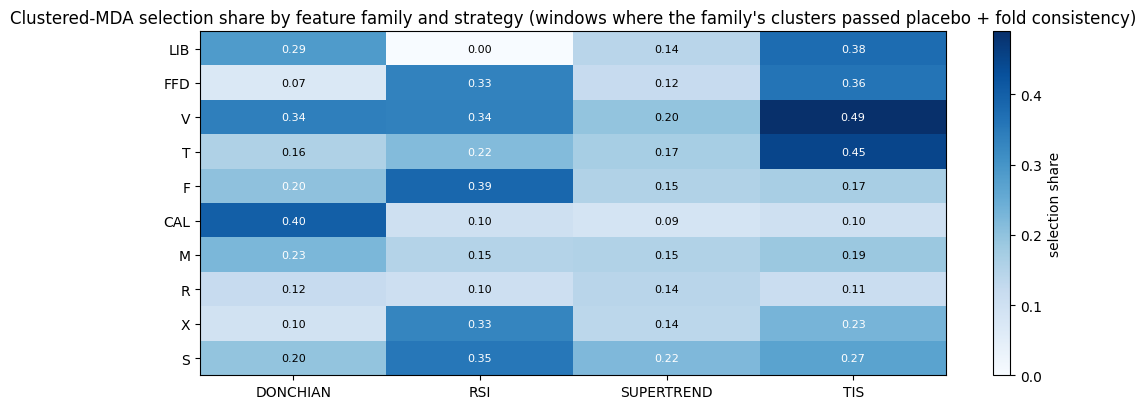

In [13]:
FEAT = ml.feature_selection_records(DIAG, FAMILY)
fam_tab = ml.family_selection_table(FEAT)
placebo_sel = FEAT.loc[FEAT["family"].eq("PLACEBO")].assign(
    above=lambda x: (x["cluster_mda"] > 0) & (x["folds_positive"] >= 3))["above"].mean()
print(f"placebo features with positive mean importance on >= 3 folds (the chance rate of the consistency rule): {placebo_sel:.3f}")
print("Selection share of a family's features by strategy (fraction of windows in which the feature's cluster was selected):")
display(fam_tab["sel_share"].round(3))
ffd_sel = FEAT.loc[FEAT["family"].eq("FFD")].groupby(["feature", "strategy"])["selected"].mean().unstack("strategy")
print("Selection share of the FFD features (price and volume levels made stationary):")
display(ffd_sel.round(3))
print("Mean attributed cluster MDA (x 1e4, increase in log loss) by family and strategy:")
display((fam_tab["mean_mda"] * 1e4).round(2))

fig, ax = plt.subplots(figsize=(10, 4.2))
hm = fam_tab["sel_share"].reindex(list(qf.FAMILY_ORDER))
im = ax.imshow(hm.to_numpy(), cmap="Blues", vmin=0, vmax=max(0.3, np.nanmax(hm.to_numpy())), aspect="auto")
ax.set_xticks(range(hm.shape[1])); ax.set_xticklabels(hm.columns); ax.set_yticks(range(hm.shape[0])); ax.set_yticklabels(hm.index)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        ax.text(j, i, f"{hm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8, color="black" if hm.iloc[i, j] < 0.2 else "white")
plt.colorbar(im, ax=ax, label="selection share")
ax.set_title("Clustered-MDA selection share by feature family and strategy (windows where the family's clusters passed placebo + fold consistency)")
fig.tight_layout(); plt.show()

In [14]:
top_rows = []
for s in SS:
    f = FEAT.loc[FEAT["strategy"].eq(s) & ~FEAT["family"].eq("PLACEBO")].groupby("feature").agg(
        family=("family", "first"), sel_share=("selected", "mean"), mean_mda=("cluster_mda", "mean"), windows=("window", "nunique"),
        mean_cluster_size=("cluster_size", "mean"))
    f = f.sort_values(["sel_share", "mean_mda"], ascending=False).head(10)
    f.insert(0, "strategy", s)
    top_rows.append(f.reset_index())
top = pd.concat(top_rows).set_index(["strategy", "feature"])
top["mean_mda"] = top["mean_mda"] * 1e4
print("Top 10 features per strategy by selection share (mean_mda x 1e4):")
top.round(3)

Top 10 features per strategy by selection share (mean_mda x 1e4):


family  sel_share  mean_mda  windows  mean_cluster_size
strategy   feature                                                                    
RSI        s_open_positions         S      1.000    14.732        8              4.875
           xr_eff_20                X      1.000    14.732        8              4.875
           xr_ema50_dist_atr        X      1.000    14.732        8              4.875
           xr_rsi14                 X      1.000    14.732        8              4.875
           f_qvol_rel_7d            F      0.875    34.994        8              3.750
           f_vol_z_20               F      0.875    34.994        8              3.750
           ffd_log_volume         FFD      0.875    31.936        8              3.625
           s_signals_24h            S      0.875    13.988        8              4.500
           ffd_log_volume_z       FFD      0.857    35.160        7              4.000
           t_ret_3d                 T      0.625     9.140        8              8.625
DONCHIAN   cal_dow_sin            CAL      0.857     5.272        7              2.000
           cal_weekend            CAL      0.857     5.272        7              2.000
           lib_adx_value          LIB      0.714    16.258        7              1.000
           m_ret_1d                 M      0.714     9.753        7              2.000
           m_ret_1d_z               M      0.714     9.753        7              2.000
           f_taker_imb_18           F      0.714     8.194        7              2.571
           f_taker_imb_42           F      0.714     8.194        7              2.571
           t_ret_3d                 T      0.571    12.413        7             12.429
           v_bb_width               V      0.571    12.413        7             12.429
           m_rvol_30d               M      0.571     8.004        7              1.000
TIS        t_ema50_dist_atr         T      1.000    84.657        6              6.000
           t_rsi28                  T      1.000    84.657        6              6.000
           s_wr_asset_30            S      1.000     4.310        2              1.000
           t_ret_90d                T      0.833    33.058        6              9.000
           t_ret_90d_z              T      0.833    33.058        6              9.000
           t_eff_40                 T      0.833    30.966        6              4.000
           t_ret_7d                 T      0.833    30.966        6              4.000
           t_ret_7d_z               T      0.833    30.966        6              4.000
           lib_atr_value_rel      LIB      0.833    14.092        6              9.500
           v_atr_rel                V      0.833    14.092        6              9.500
SUPERTREND m_avg_corr_30d           M      0.571    11.626        7              1.143
           m_rvol_30d               M      0.429    13.559        7              1.143
           t_eff_40                 T      0.429     6.003        7              3.000
           t_ret_7d                 T      0.429     6.003        7              3.000
           t_ret_7d_z               T      0.429     6.003        7              3.000
           lib_st_adx             LIB      0.429     5.961        7              1.000
           t_ret_14d                T      0.429     4.331        7              2.000
           t_ret_14d_z              T      0.429     4.331        7              2.000
           t_eff_20                 T      0.429     2.760        7              1.000
           v_rvol_ratio_1d_30d      V      0.429     1.309        7              2.000

### 7.3 MDI and the PCA eigen-rank check

Clustered MDI (in-sample, forest with one feature per split) is compared with the out-of-sample clustered MDA: a Spearman rank
correlation between the two across clusters, per window. AFML §8.4.2 proposes a further check that does not use the labels at all:
if the forest's importance ranks line up with the PCA eigen-ranks of the features, the importance is less likely to be an
overfitting artefact. Here: on the last window's training set of each strategy, MDI of a forest trained on the principal components
vs the inverse eigen-rank (weighted Kendall tau), with a label-permutation null. The ONC cluster count (MLAM §4.4) on the same training
set is shown next to the redundancy-cluster count.

In [15]:
rows = []
for (s, w0), d in DIAG.items():
    imp = d["mda"].drop(columns=["_base", "_prior"]).mean()
    common = [g for g in d["groups"] if g in imp.index and g in d["mdi"]]
    rows.append({"strategy": s, "window": w0.date(), "spearman(MDI, MDA) across clusters": spearmanr([d["mdi"][g] for g in common], [imp[g] for g in common]).statistic})
mdi_mda = pd.DataFrame(rows)
print("Spearman(MDI, MDA) across clusters, by strategy (mean over windows):")
display(mdi_mda.groupby("strategy")["spearman(MDI, MDA) across clusters"].agg(["mean", "min", "max"]).round(3))

pca_rows = []
for s in SS:
    w0 = max(w for (ss, w) in DIAG if ss == s)
    d = DIAG[(s, w0)]
    g = trades.loc[trades["strategy"].eq(s) & trades["asset"].isin(SEEN) & (trades["exit_time"] < w0)]
    usable = [c for grp in d["groups"].values() for c in grp]
    Z = g[usable].fillna(g[usable].median())
    chk_pca = fs.pca_eigen_rank_check(Z, g["y"].to_numpy(), n_null=10, seed=SEED)
    onc = fs.onc_clusters(Z, max_clusters=ONC_MAX_CLUSTERS, n_init=ONC_N_INIT, seed=SEED)
    pca_rows.append({"strategy": s, "window": w0.date(), "features": len(usable), "redundancy clusters": len(d["groups"]),
                     "ONC clusters": len(onc), "PCs for 95 %": chk_pca["n_components"], "PC1 variance": chk_pca["pc1_variance"],
                     "weighted tau (MDI on PCs vs eigen-rank)": chk_pca["tau"], "null mean": chk_pca["null_mean"],
                     "null 95th pct": chk_pca["null_p95"]})
pd.DataFrame(pca_rows).set_index("strategy").round(3)

Spearman(MDI, MDA) across clusters, by strategy (mean over windows):


,mean,min,max
strategy,,,
DONCHIAN,-0.118,-0.407,0.105
RSI,0.040,-0.135,0.163
SUPERTREND,-0.024,-0.184,0.229
TIS,0.007,-0.205,0.187


,window,features,redundancy clusters,ONC clusters,PCs for 95 %,PC1 variance,weighted tau (MDI on PCs vs eigen-rank),null mean,null 95th pct
strategy,,,,,,,,,
RSI,2026-03-01,142,67,2,61,0.210,0.258,-0.019,0.150
DONCHIAN,2026-03-01,152,70,2,61,0.221,0.099,0.052,0.185
TIS,2026-03-01,145,70,2,59,0.206,0.222,0.025,0.187
SUPERTREND,2026-03-01,151,82,2,68,0.144,0.104,0.034,0.185


### 7.4 Selected features vs the full set on the same events

Outer (walk-forward) log loss relative to the strategy's training prior, AUC, and the rank correlation of the probability with the
realised return, for every `(model, feature set)` combination, on the same events: only windows in which at least one cluster was
selected are used for the `FULL` vs `SEL` comparison. Negative Δ log loss = better than the prior.

In [16]:
PROBS = ml.probability_columns(pred)            # {"HGB-FULL": "p_HGB-FULL", ..., "META": "p"}


def combo_table(df):
    return qe.probability_quality_table(df, PROBS, n_boot=N_BOOT, seed=SEED)


has_sel = pred["p_LR-SEL"].notna() if "p_LR-SEL" in pred.columns else pd.Series(False, index=pred.index)
print(f"events in windows with a selected set: {int(has_sel.sum())} of {len(pred)}")
COMBO = {}
for grp in ["SEEN", "NEW"]:
    sub = pred.loc[pred["group"].eq(grp) & has_sel]
    if len(sub):
        COMBO[grp] = combo_table(sub)
        print(f"\n{grp} assets, windows with a selected set (n = {len(sub)}):")
        display(COMBO[grp].round(4))

events in windows with a selected set: 20465 of 20465



SEEN assets, windows with a selected set (n = 10816):


,n,Δ log loss vs prior,CI low,CI high,AUC,Brier,IC(return),IC(label)
combo,,,,,,,,
HGB-FULL,10816,0.0278,0.0165,0.0422,0.5781,0.2343,0.0290,0.0334
HGB-SEL,10816,0.0127,0.0045,0.0227,0.5897,0.2291,0.0430,0.0499
LR-FULL,10816,0.0002,-0.0020,0.0024,0.5960,0.2245,0.0442,0.0486
LR-PCA,10816,0.0043,0.0009,0.0088,0.5891,0.2262,0.0349,0.0332
LR-SEL,10816,-0.0002,-0.0041,0.0040,0.6033,0.2243,0.0511,0.0752
RF-FULL,10816,0.0005,-0.0025,0.0037,0.5991,0.2246,0.0167,0.0489
RF-SEL,10816,0.0033,-0.0015,0.0088,0.5978,0.2260,0.0475,0.0611
META,10816,0.0025,-0.0021,0.0075,0.6004,0.2255,0.0448,0.0693



NEW assets, windows with a selected set (n = 9649):


,n,Δ log loss vs prior,CI low,CI high,AUC,Brier,IC(return),IC(label)
combo,,,,,,,,
HGB-FULL,9649,0.0218,0.0133,0.0320,0.5817,0.2275,-0.0121,0.0133
HGB-SEL,9649,0.0126,0.0064,0.0199,0.5879,0.2243,0.0039,0.0392
LR-FULL,9649,0.0008,-0.0025,0.0039,0.5964,0.2195,0.0155,0.0398
LR-PCA,9649,0.0061,0.0027,0.0098,0.5838,0.2218,-0.0088,0.0119
LR-SEL,9649,0.0005,-0.0037,0.0049,0.6024,0.2193,0.0209,0.0718
RF-FULL,9649,0.0032,-0.0007,0.0069,0.5918,0.2207,-0.0342,0.0152
RF-SEL,9649,0.0059,0.0009,0.0116,0.5941,0.2218,0.0110,0.0606
META,9649,0.0057,0.0008,0.0111,0.5950,0.2217,0.0119,0.0637


## 8. Models and validation: outer walk-forward results

### 8.1 Probability quality by model, asset group and period

All events (every fitted window). `META` is the per-window choice by inner log loss. The reference prior is the training win rate
of the strategy at the time of the window.

In [17]:
for grp in ["SEEN", "NEW"]:
    sub = pred.loc[pred["group"].eq(grp)]
    print(f"\n{grp} assets, all windows (n = {len(sub)}):")
    # every window has a selected set here, so the table equals the previous one; recomputed only otherwise
    display((COMBO[grp] if grp in COMBO and len(sub) == len(pred.loc[pred["group"].eq(grp) & has_sel]) else combo_table(sub)).round(4))


SEEN assets, all windows (n = 10816):


,n,Δ log loss vs prior,CI low,CI high,AUC,Brier,IC(return),IC(label)
combo,,,,,,,,
HGB-FULL,10816,0.0278,0.0165,0.0422,0.5781,0.2343,0.0290,0.0334
HGB-SEL,10816,0.0127,0.0045,0.0227,0.5897,0.2291,0.0430,0.0499
LR-FULL,10816,0.0002,-0.0020,0.0024,0.5960,0.2245,0.0442,0.0486
LR-PCA,10816,0.0043,0.0009,0.0088,0.5891,0.2262,0.0349,0.0332
LR-SEL,10816,-0.0002,-0.0041,0.0040,0.6033,0.2243,0.0511,0.0752
RF-FULL,10816,0.0005,-0.0025,0.0037,0.5991,0.2246,0.0167,0.0489
RF-SEL,10816,0.0033,-0.0015,0.0088,0.5978,0.2260,0.0475,0.0611
META,10816,0.0025,-0.0021,0.0075,0.6004,0.2255,0.0448,0.0693



NEW assets, all windows (n = 9649):


,n,Δ log loss vs prior,CI low,CI high,AUC,Brier,IC(return),IC(label)
combo,,,,,,,,
HGB-FULL,9649,0.0218,0.0133,0.0320,0.5817,0.2275,-0.0121,0.0133
HGB-SEL,9649,0.0126,0.0064,0.0199,0.5879,0.2243,0.0039,0.0392
LR-FULL,9649,0.0008,-0.0025,0.0039,0.5964,0.2195,0.0155,0.0398
LR-PCA,9649,0.0061,0.0027,0.0098,0.5838,0.2218,-0.0088,0.0119
LR-SEL,9649,0.0005,-0.0037,0.0049,0.6024,0.2193,0.0209,0.0718
RF-FULL,9649,0.0032,-0.0007,0.0069,0.5918,0.2207,-0.0342,0.0152
RF-SEL,9649,0.0059,0.0009,0.0116,0.5941,0.2218,0.0110,0.0606
META,9649,0.0057,0.0008,0.0111,0.5950,0.2217,0.0119,0.0637


In [18]:
rows = []
for (grp, per, s), g in pred.groupby(["group", "period", "strategy"]):
    if len(g) < 100:
        continue
    m, lo, hi = qe.delta_log_loss_ci(g, "p", n_boot=N_BOOT, seed=SEED)
    rows.append({"group": grp, "period": per, "strategy": s, "n": len(g), "win rate": g["y"].mean(), "prior (mean)": g["prior"].mean(),
                 "Δ log loss": m, "CI low": lo, "CI high": hi, "AUC": qe.auc_safe(g["y"], g["p"]),
                 "IC(return)": qe.information_coefficient(g), "IC(label)": qe.information_coefficient(g, target="y")})
by_block = pd.DataFrame(rows).set_index(["group", "period", "strategy"])
print("META by asset group, period and strategy (Δ log loss vs the training prior, monthly block bootstrap CI):")
by_block.round(4)

META by asset group, period and strategy (Δ log loss vs the training prior, monthly block bootstrap CI):


n  win rate  prior (mean)  Δ log loss  CI low  CI high     AUC  IC(return)  IC(label)
group period strategy                                                                                            
NEW   A      DONCHIAN     356    0.5000        0.5650      0.0137 -0.0254   0.0559  0.5551      0.1228     0.0990
             RSI         1223    0.2715        0.3041      0.0165  0.0016   0.0340  0.5498     -0.0464     0.0739
             SUPERTREND   505    0.3842        0.3900      0.0068 -0.0119   0.0247  0.5406      0.0498     0.0765
             TIS          105    0.3619        0.3636      0.0019 -0.0478   0.0510  0.5884      0.0785     0.1474
      B      DONCHIAN    1072    0.4655        0.5488      0.0076 -0.0039   0.0197  0.4832      0.0581     0.0678
             RSI         2944    0.2551        0.2967      0.0039 -0.0021   0.0106  0.5096     -0.0457     0.0203
             SUPERTREND  2202    0.3987        0.3879      0.0005 -0.0071   0.0085  0.5342      0.0751     0.0759
             TIS          950    0.3095        0.3525      0.0064 -0.0184   0.0342  0.5495     -0.0102     0.1128
      C      RSI          119    0.2437        0.2950      0.0022  0.0003   0.0336  0.5004     -0.1470     0.0009
SEEN  A      DONCHIAN     394    0.5736        0.5651      0.0153 -0.0180   0.0502  0.5531      0.0970     0.0712
             RSI         1497    0.2993        0.3044     -0.0077 -0.0197   0.0030  0.5959      0.0404     0.1548
             SUPERTREND   589    0.3582        0.3901     -0.0009 -0.0208   0.0193  0.5742      0.0745     0.1126
      B      DONCHIAN    1186    0.5110        0.5476      0.0052 -0.0057   0.0156  0.5302      0.0918     0.0848
             RSI         3252    0.2906        0.2965      0.0018 -0.0033   0.0070  0.5272      0.0288     0.0419
             SUPERTREND  2502    0.4017        0.3881      0.0055 -0.0033   0.0135  0.5031      0.0377     0.0247
             TIS          986    0.3073        0.3522      0.0086 -0.0183   0.0366  0.5598      0.0235     0.1173
      C      RSI          119    0.2689        0.2950      0.0065  0.0024   0.0499  0.4874     -0.1262    -0.0190
             SUPERTREND   113    0.3805        0.3965      0.0134 -0.0079   0.0440  0.4186     -0.1635    -0.1366

### 8.2 Calibration

Reliability by decile of the calibrated `META` probability: mean predicted probability vs realised win rate, with the expected
calibration error (ECE, probability-weighted mean absolute gap) for the raw and the Platt-calibrated probabilities. Because the
sizing rules of §9 read the probability as a win probability (AFML §10.3), calibration — not just ranking — matters.

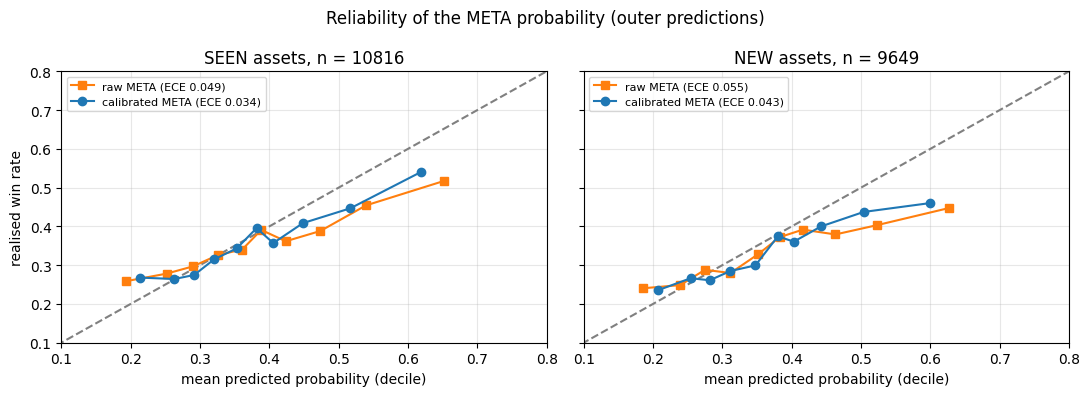

n  ECE raw  ECE calibrated  mean p  win rate
group strategy                                                   
SEEN  RSI         4868   0.0563          0.0348  0.3068    0.2927
      DONCHIAN    1626   0.0751          0.0651  0.5644    0.5283
      TIS         1118   0.1135          0.0796  0.3848    0.3265
      SUPERTREND  3204   0.0628          0.0459  0.4002    0.3929
NEW   RSI         4286   0.0712          0.0518  0.3010    0.2594
      DONCHIAN    1478   0.0897          0.0959  0.5419    0.4750
      TIS         1096   0.0897          0.0628  0.3620    0.3157
      SUPERTREND  2789   0.0478          0.0405  0.3989    0.3948

In [19]:
pred["p_raw"] = [r[f"p_{m}_raw"] for r, m in zip(pred.to_dict("records"), pred["meta"])]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
cal_rows = []
for ax, grp in zip(axes, ["SEEN", "NEW"]):
    sub = pred.loc[pred["group"].eq(grp)]
    t_cal, ece_cal = qe.reliability_table(sub, "p")
    t_raw, ece_raw = qe.reliability_table(sub, "p_raw")
    ax.plot([0, 1], [0, 1], color="gray", ls="--")
    ax.plot(t_raw["mean_p"], t_raw["win_rate"], marker="s", color="tab:orange", label=f"raw META (ECE {ece_raw:.3f})")
    ax.plot(t_cal["mean_p"], t_cal["win_rate"], marker="o", color="tab:blue", label=f"calibrated META (ECE {ece_cal:.3f})")
    ax.set_xlim(0.1, 0.8); ax.set_ylim(0.1, 0.8); ax.set_xlabel("mean predicted probability (decile)"); ax.set_title(f"{grp} assets, n = {len(sub)}")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
    for s in SS:
        ss = sub.loc[sub["strategy"].eq(s)]
        _, e1 = qe.reliability_table(ss, "p"); _, e0 = qe.reliability_table(ss, "p_raw")
        cal_rows.append({"group": grp, "strategy": s, "n": len(ss), "ECE raw": e0, "ECE calibrated": e1, "mean p": ss["p"].mean(), "win rate": ss["y"].mean()})
axes[0].set_ylabel("realised win rate")
fig.suptitle("Reliability of the META probability (outer predictions)")
fig.tight_layout(); plt.show()
pd.DataFrame(cal_rows).set_index(["group", "strategy"]).round(4)

## 9. Bet sizing: how much is filtering worth, how much is sizing worth?

### 9.1 The rules

All sizes are multiples of a fixed notional (`NOTIONAL` = 10 000 USD) and every input is known when the trade is placed: the
calibrated probability `p` of the window's `META` model, the asset's 30-day realised volatility on the signal bar, and constants
estimated on the training trades of the window (inner out-of-fold probabilities): the break-even win rate
`p_be = L / (W + L)` from the average winning and losing trade (AFML §15.2–15.3), the threshold `τ` maximising the inner
out-of-fold net PnL, the empirical CDF of the inner out-of-fold probabilities, the median volatility, and the mean of every rule
on the training trades, by which the rule is divided so that **every rule has the same expected exposure per signal** (the same
capital budget; a rule that skips trades puts proportionally more into the trades it takes). A position limit of 10 × NOTIONAL
applies to every rule.

| Rule | Size | Question it answers |
|---|---|---|
| `U` | 1 | take every signal with the same size (the primary strategy as is) |
| `D` | `clip(median_train(σ) / σ, 0.25, 4)` | inverse volatility, no model |
| `F_be` | `1[p ≥ p_be]` | binary meta-filter at the break-even win rate (expected value > 0), uniform size |
| `F_tau` | `1[p ≥ τ]` | binary meta-filter with the threshold tuned inside training (Joubert's "modelling for false positives") |
| `R` | `0.5 + ECDF_train(p)` | sizing by the rank of `p` without any filtering |
| `P` | `2Φ(z) − 1`, `z = (p − p_be) / sqrt(p(1 − p))`, 0 if `z ≤ 0` | AFML Snippet 10.1 with the reference probability moved from ½ to the break-even win rate |
| `P05` | the same with reference ½ (the book's literal rule) | shows what the literal rule does to strategies that win less than half the time |
| `Pd` | `P` discretised in steps of 0.1 | AFML §10.5 |
| `D×F_tau`, `D×F_be`, `D×R`, `D×P` | products | what the meta-model adds **on top of** inverse-volatility sizing |

**Class 0 and strategies with win rate below ½.** AFML's rule bets `2Φ(z) − 1` on the predicted class, with `z` the t-value of the
hypothesis that the probability of that class exceeds ½. In meta-labeling the predicted class 0 means "do not trade", so the literal
rule only trades when `p > ½`. Three of the four strategies win less than half of their trades and are nonetheless profitable because
winners are larger than losers (table in §5); for them `p > ½` almost never happens and the literal rule abstains almost always
(`P05` below). The null hypothesis that makes economic sense is "the expected value of the trade is zero", i.e. `p = p_be` with the
strategy's own payouts (AFML ch. 15 derives the same break-even precision from the payouts); the z-statistic is therefore centred at
`p_be`, estimated on the training trades. `P` filters (size 0 when `p ≤ p_be`) *and* sizes, which is why `F_be` is also reported:
`P − F_be` isolates the sizing part on the same accepted trades, `F_be − U` the filtering part.

**Why no "averaging of active bets" (AFML §10.4) and no dynamic limit-price sizing (§10.6).** §10.4 averages the sizes of
overlapping bets on the same instrument; here a strategy holds at most one position per asset, so there is nothing to average
(concurrency across assets is handled through the capital budget in §9.4). §10.6 needs a price forecast, which none of the primary
strategies produces.

Implementation: `quant_forge.sizing` (`afml_bet_size`, `rule_sizes`, `fit_sizing_constants`, `normalized_sizes`).

In [20]:
RULES = list(qz.SIZING_RULES)
SIZE, SIZE_UNCAPPED = qz.normalized_sizes(pred, {k: d["constants"] for k, d in DIAG.items()}, cap=SIZE_CAP, return_uncapped=True)
print(f"share of trades hitting the {SIZE_CAP:.0f} x NOTIONAL position limit, by rule:", (SIZE_UNCAPPED > SIZE_CAP).mean().round(4).to_dict())
consts = ml.sizing_constants_table(DIAG)
print("Training-side sizing constants per window (p_be = break-even win rate; tau = tuned filter threshold):")
display(consts.groupby("strategy")[["prior", "p_be", "tau quantile", "train share p ≥ p_be", "train share p ≥ 0.5", "norm P", "norm P05"]].mean().round(3))
print("Size distribution by rule (multiples of NOTIONAL), NEW assets:")
_S = SIZE.loc[pred["group"].eq("NEW")]
display(pd.DataFrame({"mean": _S.mean(), "median": _S.median(), "p90": _S.quantile(0.9), "p99": _S.quantile(0.99), "max": _S.max()}).T.round(2))
print("Realised share of signals traded (size > 0) by rule, NEW assets:")
display((SIZE.loc[pred["group"].eq("NEW")] > 0).groupby(pred.loc[pred["group"].eq("NEW"), "strategy"]).mean().round(3))

share of trades hitting the 10 x NOTIONAL position limit, by rule: {'U': 0.0, 'D': 0.0, 'F_tau': 0.0, 'F_be': 0.0, 'R': 0.0, 'P': 0.0, 'P05': 0.0191, 'Pd': 0.0, 'DxF_tau': 0.0, 'DxF_be': 0.0, 'DxR': 0.0, 'DxP': 0.0006}
Training-side sizing constants per window (p_be = break-even win rate; tau = tuned filter threshold):


,prior,p_be,tau quantile,train share p ≥ p_be,train share p ≥ 0.5,norm P,norm P05
strategy,,,,,,,
DONCHIAN,0.551,0.357,0.043,0.968,0.773,0.311,0.108
RSI,0.299,0.240,0.188,0.816,0.014,0.112,0.001
SUPERTREND,0.389,0.353,0.371,0.748,0.060,0.073,0.005
TIS,0.352,0.212,0.150,0.895,0.100,0.229,0.008


Size distribution by rule (multiples of NOTIONAL), NEW assets:


,U,D,F_tau,F_be,R,P,P05,Pd,DxF_tau,DxF_be,DxR,DxP
mean,1.0,0.92,1.04,1.04,1.00,1.05,0.41,1.02,0.94,0.94,0.90,0.92
median,1.0,0.88,1.11,1.10,1.00,0.96,0.00,0.94,0.92,0.95,0.80,0.74
p90,1.0,1.40,1.54,1.39,1.40,2.19,0.98,2.23,1.74,1.63,1.52,1.94
p99,1.0,2.10,3.33,1.88,1.49,4.02,10.00,4.39,3.33,2.44,2.48,4.23
max,1.0,2.73,3.33,1.88,1.50,6.34,10.00,7.83,6.07,3.37,3.61,9.38


Realised share of signals traded (size > 0) by rule, NEW assets:


,U,D,F_tau,F_be,R,P,P05,Pd,DxF_tau,DxF_be,DxR,DxP
strategy,,,,,,,,,,,,
DONCHIAN,1.0,1.0,0.938,0.968,1.0,0.968,0.719,0.958,0.938,0.968,1.0,0.968
RSI,1.0,1.0,0.798,0.841,1.0,0.841,0.025,0.682,0.798,0.841,1.0,0.841
SUPERTREND,1.0,1.0,0.697,0.809,1.0,0.809,0.066,0.500,0.697,0.809,1.0,0.809
TIS,1.0,1.0,0.852,0.911,1.0,0.911,0.099,0.862,0.852,0.911,1.0,0.911


### 9.2 Economics

Monthly PnL by exit month (`NOTIONAL × size × trade_return`), every calendar month of the scope included. Sharpe is annualised
from monthly PnL. Differences between rules use a **paired monthly block bootstrap** (same resampled months for both rules) and,
for the rules that use the model, a **permutation test**: sizes are shuffled among the trades of the same strategy and window
(same size distribution, no information), and the p-value is the share of shuffles whose Sharpe gain over `U` is at least the
observed one. The capital budget `K` of a scope is the 95th percentile of the gross open exposure of `U` in that scope, the same for
every rule; "return on K" is annualised PnL / K; drawdown is on cumulative PnL relative to `K`; exposure is the time-weighted
average gross open notional / `K`; concurrency counts simultaneous open positions.

Implementation: `quant_forge.evaluation.evaluate_sizing` (table, monthly PnL, paired bootstrap Sharpe samples, budget).

In [21]:
def econ(df, W, rules=RULES, perm_rules=("F_tau", "F_be", "R", "P", "Pd", "DxF_tau", "DxF_be", "DxR", "DxP")):
    return qe.evaluate_sizing(df, W, rules=rules, perm_rules=perm_rules, notional=NOTIONAL, n_boot=N_BOOT,
                              n_perm=N_PERM_TEST, seed=SEED)


ECON = {}
for grp in ["NEW", "SEEN"]:
    for per in ["all", "A", "B", "C"]:
        m = pred["group"].eq(grp) & (pred["period"].eq(per) if per != "all" else True)
        if m.sum() > 200 and pred.loc[m, "month"].nunique() >= 6:
            ECON[(grp, per)] = econ(pred.loc[m], SIZE.loc[m])
            print(f"{grp} assets, period {per}: n = {int(m.sum())}, months = {ECON[(grp, per)].months}, K = {ECON[(grp, per)].budget / 1e3:.0f} kUSD")
            display(ECON[(grp, per)].table.round(3))

NEW assets, period all: n = 9649, months = 93, K = 350 kUSD


,Sharpe,Δ vs U,CI U lo,CI U hi,Δ vs D,CI D lo,CI D hi,p perm,PnL (kUSD),return on K (ann.),bps / notional,max DD / K,exposure / K,traded,mean open pos.,max open pos.
rule,,,,,,,,,,,,,,,,
U,0.701,0.000,0.000,0.000,-0.180,-0.406,0.003,NaN,800.024,0.295,82.913,-0.316,0.494,1.000,17.305,77.0
D,0.881,0.180,-0.003,0.406,0.000,0.000,0.000,NaN,879.978,0.324,98.698,-0.337,0.448,1.000,17.305,77.0
F_tau,0.801,0.100,-0.067,0.299,-0.080,-0.341,0.168,0.074,1073.781,0.396,107.079,-0.429,0.554,0.797,13.142,69.0
F_be,0.794,0.093,-0.005,0.214,-0.087,-0.317,0.122,0.020,1030.039,0.380,102.391,-0.402,0.534,0.859,14.706,75.0
R,0.776,0.075,-0.009,0.190,-0.105,-0.326,0.095,0.002,980.215,0.361,101.730,-0.335,0.512,1.000,17.305,77.0
P,0.907,0.206,-0.001,0.489,0.026,-0.228,0.307,0.002,1509.003,0.556,148.511,-0.355,0.596,0.859,14.706,75.0
P05,0.882,0.181,-0.220,0.664,0.001,-0.430,0.485,NaN,1579.581,0.582,394.627,-0.261,0.257,0.152,2.450,26.0
Pd,0.921,0.220,-0.021,0.541,0.040,-0.245,0.336,0.006,1520.611,0.561,154.984,-0.360,0.555,0.692,10.682,71.0
DxF_tau,0.939,0.238,-0.024,0.532,0.058,-0.136,0.249,0.002,960.997,0.354,106.384,-0.475,0.490,0.797,13.142,69.0


NEW assets, period A: n = 2189, months = 32, K = 250 kUSD


,Sharpe,Δ vs U,CI U lo,CI U hi,Δ vs D,CI D lo,CI D hi,p perm,PnL (kUSD),return on K (ann.),bps / notional,max DD / K,exposure / K,traded,mean open pos.,max open pos.
rule,,,,,,,,,,,,,,,,
U,0.887,0.000,0.000,0.000,-0.084,-0.427,0.178,NaN,365.189,0.548,166.829,-0.212,0.385,1.000,9.636,45.0
D,0.971,0.084,-0.178,0.427,0.000,0.000,0.000,NaN,166.947,0.250,110.369,-0.108,0.244,1.000,9.636,45.0
F_tau,1.051,0.163,-0.004,0.562,0.080,-0.254,0.504,0.026,586.971,0.880,234.276,-0.208,0.474,0.819,7.867,38.0
F_be,1.070,0.183,0.059,0.549,0.099,-0.207,0.468,0.004,534.772,0.802,212.383,-0.207,0.442,0.811,8.107,42.0
R,0.979,0.092,-0.002,0.311,0.008,-0.300,0.324,0.006,508.213,0.762,216.404,-0.201,0.414,1.000,9.636,45.0
P,1.077,0.190,-0.052,0.709,0.106,-0.302,0.601,0.034,808.786,1.213,288.030,-0.236,0.481,0.811,8.107,42.0
P05,1.342,0.455,0.085,1.135,0.371,-0.091,0.934,NaN,1263.343,1.895,727.910,-0.297,0.346,0.193,2.099,18.0
Pd,1.086,0.199,-0.058,0.713,0.115,-0.304,0.608,0.032,791.928,1.188,283.916,-0.232,0.482,0.740,7.355,38.0
DxF_tau,1.239,0.352,0.072,0.883,0.268,0.027,0.628,0.004,284.513,0.427,168.878,-0.087,0.299,0.819,7.867,38.0


NEW assets, period B: n = 7168, months = 61, K = 370 kUSD


,Sharpe,Δ vs U,CI U lo,CI U hi,Δ vs D,CI D lo,CI D hi,p perm,PnL (kUSD),return on K (ann.),bps / notional,max DD / K,exposure / K,traded,mean open pos.,max open pos.
rule,,,,,,,,,,,,,,,,
U,0.597,0.000,0.000,0.000,-0.310,-0.558,-0.116,NaN,431.760,0.230,60.234,-0.299,0.562,1.000,20.785,77.0
D,0.906,0.310,0.116,0.558,0.000,0.000,0.000,NaN,694.631,0.369,97.181,-0.319,0.546,1.000,20.785,77.0
F_tau,0.618,0.022,-0.222,0.301,-0.288,-0.621,0.057,0.390,453.719,0.241,62.771,-0.406,0.616,0.788,15.532,69.0
F_be,0.599,0.003,-0.136,0.168,-0.307,-0.587,-0.036,0.402,466.667,0.248,64.454,-0.380,0.598,0.872,17.703,75.0
R,0.641,0.044,-0.086,0.195,-0.265,-0.526,-0.023,0.132,459.499,0.244,65.761,-0.317,0.577,1.000,20.785,77.0
P,0.803,0.206,-0.122,0.580,-0.104,-0.455,0.247,0.018,673.157,0.358,95.215,-0.336,0.676,0.872,17.703,75.0
P05,0.552,-0.045,-0.766,0.610,-0.355,-1.112,0.292,NaN,315.398,0.168,143.850,-0.247,0.247,0.138,2.563,26.0
Pd,0.820,0.223,-0.189,0.680,-0.086,-0.522,0.295,0.038,702.544,0.374,104.347,-0.340,0.616,0.675,12.084,71.0
DxF_tau,0.853,0.257,-0.062,0.640,-0.053,-0.320,0.203,0.010,632.325,0.336,89.134,-0.449,0.586,0.788,15.532,69.0


... (2 outputs left out)

SEEN assets, period A: n = 2571, months = 31, K = 280 kUSD


,Sharpe,Δ vs U,CI U lo,CI U hi,Δ vs D,CI D lo,CI D hi,p perm,PnL (kUSD),return on K (ann.),bps / notional,max DD / K,exposure / K,traded,mean open pos.,max open pos.
rule,,,,,,,,,,,,,,,,
U,1.498,0.000,0.000,0.000,-0.095,-0.276,0.087,NaN,624.044,0.863,242.724,-0.081,0.374,1.000,10.462,51.0
D,1.594,0.095,-0.087,0.276,0.000,0.000,0.000,NaN,507.536,0.702,218.773,-0.081,0.303,1.000,10.462,51.0
F_tau,1.624,0.125,0.020,0.302,0.030,-0.177,0.277,0.036,844.800,1.168,292.125,-0.099,0.458,0.811,8.502,42.0
F_be,1.619,0.120,0.019,0.266,0.025,-0.188,0.274,0.070,888.591,1.228,306.665,-0.089,0.428,0.795,8.755,46.0
R,1.611,0.113,0.058,0.219,0.017,-0.165,0.237,0.002,796.474,1.101,291.166,-0.085,0.407,1.000,10.462,51.0
P,1.668,0.170,-0.002,0.541,0.075,-0.198,0.515,0.058,1384.627,1.914,432.463,-0.075,0.493,0.795,8.755,46.0
P05,1.476,-0.022,-0.397,0.469,-0.118,-0.581,0.435,NaN,2001.915,2.768,895.611,-0.241,0.479,0.199,2.908,19.0
Pd,1.669,0.171,-0.020,0.585,0.075,-0.212,0.542,0.050,1446.234,1.999,451.038,-0.080,0.499,0.716,7.937,44.0
DxF_tau,1.691,0.193,0.002,0.404,0.097,-0.015,0.232,0.012,687.701,0.951,268.405,-0.088,0.373,0.811,8.502,42.0


SEEN assets, period B: n = 7926, months = 61, K = 390 kUSD


,Sharpe,Δ vs U,CI U lo,CI U hi,Δ vs D,CI D lo,CI D hi,p perm,PnL (kUSD),return on K (ann.),bps / notional,max DD / K,exposure / K,traded,mean open pos.,max open pos.
rule,,,,,,,,,,,,,,,,
U,0.803,0.000,0.000,0.000,-0.324,-0.590,-0.133,NaN,475.015,0.240,59.931,-0.126,0.550,1.000,21.433,71.0
D,1.127,0.324,0.133,0.590,0.000,0.000,0.000,NaN,957.329,0.483,95.706,-0.160,0.668,1.000,21.433,71.0
F_tau,0.926,0.123,-0.166,0.485,-0.201,-0.553,0.156,0.124,641.153,0.323,77.493,-0.187,0.606,0.819,16.407,70.0
F_be,0.819,0.016,-0.146,0.180,-0.308,-0.605,-0.064,0.392,542.557,0.274,65.738,-0.179,0.593,0.895,18.571,70.0
R,0.864,0.060,-0.062,0.210,-0.263,-0.539,-0.035,0.148,542.085,0.273,66.321,-0.158,0.581,1.000,21.433,71.0
P,0.941,0.138,-0.213,0.526,-0.186,-0.553,0.191,0.180,720.953,0.364,82.500,-0.311,0.680,0.895,18.571,70.0
P05,0.742,-0.061,-0.752,0.629,-0.385,-1.055,0.197,NaN,450.268,0.227,142.798,-0.268,0.258,0.161,3.087,28.0
Pd,0.877,0.074,-0.350,0.524,-0.250,-0.676,0.176,0.346,655.849,0.331,78.649,-0.327,0.620,0.713,12.769,66.0
DxF_tau,1.142,0.339,0.036,0.744,0.015,-0.211,0.288,0.014,1113.982,0.562,107.143,-0.211,0.725,0.819,16.407,70.0


### 9.3 Decomposition: filtering vs sizing, with uncertainty

Paired Sharpe differences (monthly block bootstrap, 95 % CI) on the `NEW` assets (transfer) and on the `SEEN` assets:

* `F_be − U`: value of **filtering** at the break-even probability, uniform size;
* `P − F_be`: value of **changing the size** of the accepted trades by the AFML rule (same trades);
* `F_tau − U`: filtering with the tuned threshold;
* `R − U`: **sizing without filtering** (rank);
* `P − U`: the whole AFML rule;
* `D − U`: inverse volatility alone;
* `D×P − D`, `D×R − D`, `D×F_tau − D`, `D×F_be − D`: what the meta-model adds on top of inverse volatility.

In [22]:
PAIRS = [("F_be", "U"), ("P", "F_be"), ("F_tau", "U"), ("R", "U"), ("P", "U"), ("Pd", "P"), ("D", "U"), ("DxP", "D"), ("DxR", "D"),
         ("DxF_tau", "D"), ("DxF_be", "D"), ("DxP", "P")]
# the evaluations of the previous cell already hold the paired bootstrap samples (same scope, rules and seed): reuse them
DECOMP = {}
for grp in ["NEW", "SEEN"]:
    for per in ["all", "A", "B"]:
        e = ECON.get((grp, per))
        if e is None:
            m = pred["group"].eq(grp) & (pred["period"].eq(per) if per != "all" else True)
            e = econ(pred.loc[m], SIZE.loc[m], perm_rules=())
        DECOMP[(grp, per)] = qe.paired_sharpe_table(e, PAIRS)
tab = pd.concat({f"{g} {p}": v["Δ Sharpe"].map("{:+.3f}".format) + " [" + v["CI low"].map("{:+.2f}".format) + ", " + v["CI high"].map("{:+.2f}".format) + "]"
                 for (g, p), v in DECOMP.items()}, axis=1)
print("Paired Δ Sharpe [95 % CI] by asset group and period:")
tab

Paired Δ Sharpe [95 % CI] by asset group and period:


,NEW all,NEW A,NEW B,SEEN all,SEEN A,SEEN B
comparison,,,,,,
F_be − U,"+0.093 [-0.00, +0.21]","+0.183 [+0.06, +0.55]","+0.003 [-0.14, +0.17]","+0.064 [-0.03, +0.17]","+0.120 [+0.02, +0.27]","+0.016 [-0.15, +0.18]"
P − F_be,"+0.113 [-0.06, +0.33]","+0.007 [-0.20, +0.26]","+0.204 [-0.06, +0.50]","+0.068 [-0.08, +0.28]","+0.050 [-0.14, +0.38]","+0.122 [-0.15, +0.42]"
F_tau − U,"+0.100 [-0.07, +0.30]","+0.163 [-0.00, +0.56]","+0.022 [-0.22, +0.30]","+0.113 [-0.07, +0.33]","+0.125 [+0.02, +0.30]","+0.123 [-0.17, +0.48]"
R − U,"+0.075 [-0.01, +0.19]","+0.092 [-0.00, +0.31]","+0.044 [-0.09, +0.20]","+0.084 [+0.01, +0.17]","+0.113 [+0.06, +0.22]","+0.060 [-0.06, +0.21]"
P − U,"+0.206 [-0.00, +0.49]","+0.190 [-0.05, +0.71]","+0.206 [-0.12, +0.58]","+0.132 [-0.05, +0.39]","+0.170 [-0.00, +0.54]","+0.138 [-0.21, +0.53]"
Pd − P,"+0.014 [-0.09, +0.11]","+0.009 [-0.07, +0.07]","+0.017 [-0.17, +0.20]","-0.034 [-0.11, +0.05]","+0.001 [-0.03, +0.06]","-0.064 [-0.21, +0.10]"
D − U,"+0.180 [-0.00, +0.41]","+0.084 [-0.18, +0.43]","+0.310 [+0.12, +0.56]","+0.169 [+0.02, +0.34]","+0.095 [-0.09, +0.28]","+0.324 [+0.13, +0.59]"
DxP − D,"+0.228 [+0.01, +0.47]","+0.336 [-0.01, +0.80]","+0.134 [-0.15, +0.45]","+0.171 [-0.01, +0.37]","+0.262 [+0.09, +0.50]","+0.077 [-0.20, +0.37]"
DxR − D,"+0.086 [-0.00, +0.19]","+0.162 [+0.02, +0.36]","+0.035 [-0.07, +0.16]","+0.079 [+0.01, +0.15]","+0.104 [+0.04, +0.20]","+0.048 [-0.05, +0.15]"


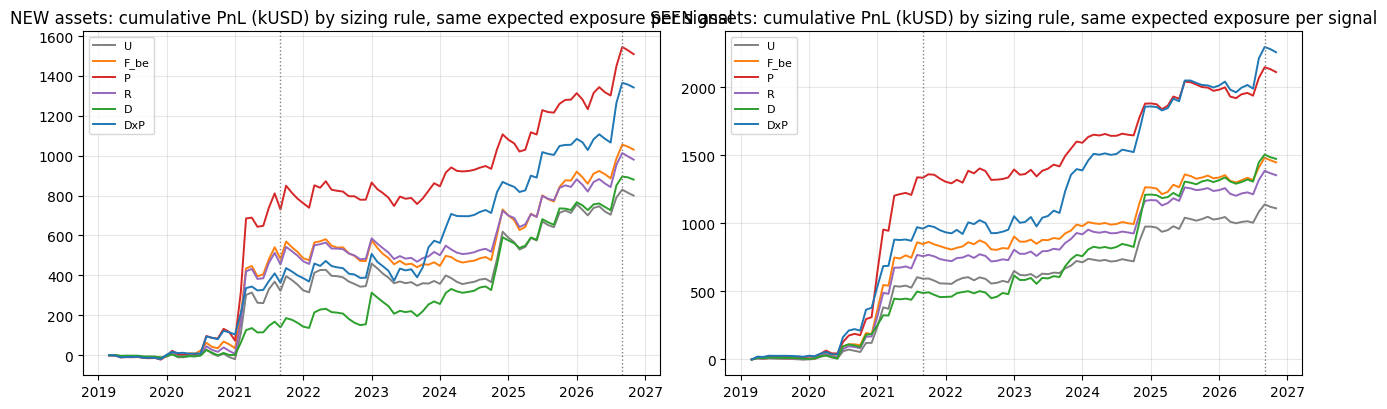

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=False)
for ax, grp in zip(axes, ["NEW", "SEEN"]):
    M = ECON[(grp, "all")].monthly
    months = pd.period_range(pred.loc[pred["group"].eq(grp), "exit_time"].min().strftime("%Y-%m"), periods=len(M["U"]), freq="M").to_timestamp()
    for r, c in [("U", "gray"), ("F_be", "tab:orange"), ("P", "tab:red"), ("R", "tab:purple"), ("D", "tab:green"), ("DxP", "tab:blue")]:
        ax.plot(months, np.cumsum(M[r]) / 1e3, label=r, color=c, lw=1.4)
    ax.set_title(f"{grp} assets: cumulative PnL (kUSD) by sizing rule, same expected exposure per signal")
    ax.axvline(A_END, color="gray", ls=":", lw=1); ax.axvline(B_END, color="gray", ls=":", lw=1)
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

### 9.4 By strategy (NEW assets): which primary strategies benefit?

For each strategy on the `NEW` assets: the META probability quality and the Sharpe effects of the main rules.

In [24]:
def strategy_table(grp):
    rows = []
    for s in SS:
        m = pred["group"].eq(grp) & pred["strategy"].eq(s)
        g = pred.loc[m]
        if len(g) < 100:
            continue
        tab_s, M, B = econ(g, SIZE.loc[m], perm_rules=("F_be", "P", "R", "DxP"))
        dl, lo, hi = qe.delta_log_loss_ci(g, "p", n_boot=N_BOOT, seed=SEED)
        sh = qe.annualized_sharpe
        cmp = lambda a, b: f"{sh(M[a]) - sh(M[b]):+.2f} [{np.quantile(B[a] - B[b], 0.025):+.2f}, {np.quantile(B[a] - B[b], 0.975):+.2f}]"
        rows.append({"strategy": s, "n": len(g), "win rate": g["y"].mean(), "Δ log loss": f"{dl:+.4f} [{lo:+.4f}, {hi:+.4f}]", "AUC": qe.auc_safe(g["y"], g["p"]),
                     "IC(return)": qe.information_coefficient(g), "Sharpe U": tab_s.loc["U", "Sharpe"], "F_be − U": cmp("F_be", "U"), "P − F_be": cmp("P", "F_be"),
                     "R − U": cmp("R", "U"), "P − U": cmp("P", "U"), "p perm P": tab_s.loc["P", "p perm"], "D − U": cmp("D", "U"),
                     "D×P − D": cmp("DxP", "D"), "D×R − D": cmp("DxR", "D"), "traded P": tab_s.loc["P", "traded"], "traded P05": tab_s.loc["P05", "traded"]})
    return pd.DataFrame(rows).set_index("strategy")


print("NEW assets, by strategy:")
display(strategy_table("NEW").round(3))
print("SEEN assets, by strategy:")
display(strategy_table("SEEN").round(3))

NEW assets, by strategy:


,n,win rate,Δ log loss,AUC,IC(return),Sharpe U,F_be − U,P − F_be,R − U,P − U,p perm P,D − U,D×P − D,D×R − D,traded P,traded P05
strategy,,,,,,,,,,,,,,,,
RSI,4286,0.259,"+0.0074 [+0.0013, +0.0140]",0.527,-0.048,-0.171,"+0.20 [+0.01, +0.43]","+0.16 [-0.12, +0.46]","+0.16 [+0.01, +0.32]","+0.36 [-0.00, +0.81]",0.014,"-0.20 [-0.69, +0.20]","+0.43 [+0.03, +0.96]","+0.17 [-0.01, +0.38]",0.841,0.025
DONCHIAN,1478,0.475,"+0.0090 [-0.0035, +0.0221]",0.506,0.071,0.842,"+0.08 [+0.02, +0.18]","-0.05 [-0.22, +0.10]","+0.04 [-0.09, +0.18]","+0.03 [-0.15, +0.24]",0.048,"-0.06 [-0.28, +0.15]","-0.00 [-0.15, +0.16]","+0.02 [-0.10, +0.14]",0.968,0.719
TIS,1096,0.316,"+0.0053 [-0.0172, +0.0283]",0.557,0.001,0.775,"-0.04 [-0.13, +0.04]","-0.05 [-0.24, +0.18]","-0.04 [-0.14, +0.10]","-0.09 [-0.32, +0.18]",0.670,"+0.13 [-0.05, +0.37]","+0.01 [-0.27, +0.23]","+0.04 [-0.10, +0.15]",0.911,0.099
SUPERTREND,2789,0.395,"+0.0013 [-0.0057, +0.0083]",0.537,0.077,0.553,"+0.15 [-0.05, +0.37]","+0.28 [+0.02, +0.58]","+0.16 [+0.02, +0.31]","+0.44 [+0.12, +0.82]",0.002,"+0.39 [+0.15, +0.64]","+0.28 [-0.00, +0.60]","+0.10 [-0.01, +0.22]",0.809,0.066


SEEN assets, by strategy:


,n,win rate,Δ log loss,AUC,IC(return),Sharpe U,F_be − U,P − F_be,R − U,P − U,p perm P,D − U,D×P − D,D×R − D,traded P,traded P05
strategy,,,,,,,,,,,,,,,,
RSI,4868,0.293,"-0.0010 [-0.0058, +0.0037]",0.549,0.028,0.846,"-0.01 [-0.11, +0.16]","-0.03 [-0.17, +0.32]","+0.06 [-0.03, +0.19]","-0.04 [-0.26, +0.44]",0.230,"+0.04 [-0.16, +0.22]","+0.14 [-0.08, +0.43]","+0.08 [+0.00, +0.20]",0.855,0.026
DONCHIAN,1626,0.528,"+0.0072 [-0.0041, +0.0191]",0.542,0.093,1.453,"+0.03 [-0.02, +0.09]","+0.08 [-0.04, +0.21]","+0.10 [+0.00, +0.19]","+0.12 [-0.03, +0.26]",0.002,"+0.06 [-0.08, +0.23]","+0.01 [-0.13, +0.16]","+0.00 [-0.10, +0.12]",0.972,0.808
TIS,1118,0.326,"+0.0049 [-0.0193, +0.0302]",0.568,0.040,0.718,"+0.03 [-0.04, +0.10]","+0.01 [-0.16, +0.16]","+0.02 [-0.09, +0.12]","+0.03 [-0.17, +0.22]",0.170,"+0.08 [-0.07, +0.42]","+0.11 [-0.11, +0.24]","+0.06 [-0.04, +0.13]",0.933,0.172
SUPERTREND,3204,0.393,"+0.0046 [-0.0030, +0.0119]",0.517,0.047,0.475,"+0.18 [-0.05, +0.40]","+0.17 [-0.14, +0.44]","+0.12 [-0.03, +0.28]","+0.35 [-0.08, +0.72]",0.050,"+0.44 [+0.08, +0.77]","+0.12 [-0.26, +0.47]","+0.04 [-0.09, +0.18]",0.816,0.065


### 9.5 Simultaneous positions and the capital budget

The rules above keep the *expected* exposure per signal equal, but signals cluster in time (many assets break out together), so
the gross open exposure fluctuates. Two views: (1) the concurrency statistics already in the tables (mean and maximum number of
open positions, time-weighted exposure); (2) a **capital-constrained** replay in which a new trade can only use the capital not
already committed: trades are processed in order of entry, the open gross exposure at entry is known, and the new size is cut to
`(K − open) / NOTIONAL` when the budget `K` would be exceeded. The replay is point-in-time (only earlier entries and exits are
used).

Implementation: `quant_forge.sizing.capital_constrained_sizes`.

In [25]:
rows = []
for grp in ["NEW", "SEEN"]:
    m = pred["group"].eq(grp)
    g = pred.loc[m].reset_index(drop=True)
    K = ECON[(grp, "all")].budget
    Wc = {r: qz.capital_constrained_sizes(g["entry_time"], g["exit_time"], SIZE.loc[m, r].to_numpy(), K, NOTIONAL)
          for r in ["U", "D", "F_be", "F_tau", "R", "P", "DxP", "DxR"]}
    tab_c, M, B = econ(g, Wc, rules=list(Wc), perm_rules=())
    tab_u = econ(g, {r: SIZE.loc[m, r].to_numpy() for r in Wc}, rules=list(Wc), perm_rules=()).table
    for r in Wc:
        rows.append({"group": grp, "rule": r, "Sharpe unconstrained": tab_u.loc[r, "Sharpe"], "Sharpe constrained": tab_c.loc[r, "Sharpe"],
                     "Δ vs U constrained": tab_c.loc[r, "Δ vs U"], "CI lo": tab_c.loc[r, "CI U lo"], "CI hi": tab_c.loc[r, "CI U hi"],
                     "PnL constrained / unconstrained": M[r].sum() / max(tab_u.loc[r, "PnL (kUSD)"] * 1e3, 1e-9),
                     "share of trades cut": float((Wc[r] < SIZE.loc[m, r].to_numpy() - 1e-12).mean()), "K (kUSD)": K / 1e3})
pd.DataFrame(rows).set_index(["group", "rule"]).round(3)

Sharpe unconstrained  Sharpe constrained  Δ vs U constrained  CI lo  CI hi  PnL constrained / unconstrained  share of trades cut  K (kUSD)
group rule                                                                                                                                             
NEW   U                     0.701               0.641               0.000  0.000  0.000                            0.841                0.089     350.0
      D                     0.881               0.740               0.099 -0.094  0.317                            0.632                0.107     350.0
      F_be                  0.794               0.718               0.077 -0.079  0.244                            0.712                0.110     350.0
      F_tau                 0.801               0.755               0.113 -0.089  0.334                            0.713                0.120     350.0
      R                     0.776               0.723               0.081 -0.023  0.210                            0.762                0.103     350.0
      P                     0.907               0.776               0.134 -0.080  0.366                            0.600                0.147     350.0
      DxP                   1.109               0.812               0.171 -0.088  0.444                            0.547                0.119     350.0
      DxR                   0.967               0.828               0.186 -0.000  0.418                            0.661                0.106     350.0
SEEN  U                     1.069               1.010               0.000  0.000  0.000                            0.819                0.073     370.0
      D                     1.238               1.143               0.133 -0.022  0.306                            0.591                0.141     370.0
      F_be                  1.133               1.030               0.020 -0.125  0.159                            0.811                0.095     370.0
      F_tau                 1.182               1.110               0.100 -0.106  0.353                            0.797                0.104     370.0
      R                     1.153               1.060               0.050 -0.044  0.155                            0.817                0.099     370.0
      P                     1.201               1.065               0.055 -0.195  0.342                            0.699                0.147     370.0
      DxP                   1.409               1.181               0.171 -0.083  0.478                            0.558                0.174     370.0
      DxR                   1.317               1.172               0.162 -0.010  0.358                            0.582                0.152     370.0

### 9.6 Robustness: tails, years, and the literal AFML rule

* Sharpe effects on the `NEW` assets after removing the 1 % most extreme trade returns (does the sizing effect live in a few trades?).
* Yearly IC of the META probability and yearly `P − U` (does it persist or is it one regime?).
* What the literal `P05` rule trades.

In [26]:
m = pred["group"].eq("NEW")
g = pred.loc[m]
q1, q99 = g["trade_return"].quantile([0.01, 0.99])
mt = m & (pred["trade_return"] > q1) & (pred["trade_return"] < q99)
print(f"NEW assets without the 1 % tails (n = {int(mt.sum())}):")
display(econ(pred.loc[mt], SIZE.loc[mt], rules=["U", "D", "F_be", "P", "R", "DxP", "DxR"], perm_rules=("P", "R", "DxP")).table[
    ["Sharpe", "Δ vs U", "CI U lo", "CI U hi", "p perm", "Δ vs D", "CI D lo", "CI D hi"]].round(3))

rows = []
for yv, gy in g.groupby(g["exit_time"].dt.year):
    if len(gy) < 150 or gy["month"].nunique() < 6:
        continue
    tab_y = econ(gy, SIZE.loc[gy.index], rules=["U", "D", "P", "R", "DxP"], perm_rules=()).table
    rows.append({"year": yv, "n": len(gy), "IC(return)": qe.information_coefficient(gy), "IC(label)": qe.information_coefficient(gy, target="y"),
                 "Δ log loss": qe.delta_log_loss_ci(gy, "p", n_boot=200, seed=SEED)[0],
                 "Sharpe U": tab_y.loc["U", "Sharpe"], "P − U": tab_y.loc["P", "Δ vs U"], "R − U": tab_y.loc["R", "Δ vs U"], "D − U": tab_y.loc["D", "Δ vs U"],
                 "D×P − D": tab_y.loc["DxP", "Δ vs D"]})
print("NEW assets by exit year:")
display(pd.DataFrame(rows).set_index("year").round(3))
print("Literal AFML rule (reference 1/2): share of signals traded by strategy, NEW assets:",
      (SIZE.loc[m, "P05"] > 0).groupby(g["strategy"]).mean().round(3).to_dict())

NEW assets without the 1 % tails (n = 9455):


,Sharpe,Δ vs U,CI U lo,CI U hi,p perm,Δ vs D,CI D lo,CI D hi
rule,,,,,,,,
U,0.268,0.000,0.000,0.000,NaN,-0.295,-0.536,-0.094
D,0.563,0.295,0.094,0.536,NaN,0.000,0.000,0.000
F_be,0.365,0.097,-0.035,0.255,NaN,-0.198,-0.445,0.043
P,0.578,0.309,0.023,0.640,0.0,0.015,-0.292,0.341
R,0.379,0.110,0.009,0.237,0.0,-0.184,-0.405,0.025
DxP,0.799,0.530,0.199,0.937,0.0,0.236,0.015,0.509
DxR,0.642,0.373,0.135,0.672,NaN,0.079,-0.000,0.185


NEW assets by exit year:


,n,IC(return),IC(label),Δ log loss,Sharpe U,P − U,R − U,D − U,D×P − D
year,,,,,,,,,
2019,168,-0.153,-0.047,0.027,-2.077,0.096,0.006,0.295,0.007
2020,945,0.067,0.121,0.007,0.061,1.229,0.528,0.224,1.120
2021,1630,0.000,0.043,0.020,1.411,0.026,0.070,0.068,0.034
2022,1181,-0.076,-0.033,0.018,-0.066,0.028,-0.069,-0.011,-0.030
2023,1669,0.028,0.027,0.004,0.197,0.398,0.071,0.438,0.304
2024,1564,-0.001,0.076,-0.004,1.360,0.461,-0.007,0.391,0.367
2025,1303,0.029,0.105,-0.003,0.646,0.399,0.163,0.298,0.252
2026,1189,0.081,0.121,-0.006,0.718,0.421,0.211,0.375,0.194


Literal AFML rule (reference 1/2): share of signals traded by strategy, NEW assets: {'DONCHIAN': 0.719, 'RSI': 0.025, 'SUPERTREND': 0.066, 'TIS': 0.099}


## 10. Summary table of the answers (computed)

The verdicts below are read off the tables above (NEW assets unless stated): the sign and the 95 % CI of each paired Sharpe
difference, the Δ log loss of META against the prior, and the selection shares of the feature families.

In [27]:
summary_rows = []
for (grp, per) in [("NEW", "all"), ("NEW", "A"), ("NEW", "B"), ("SEEN", "all")]:
    d = DECOMP[(grp, per)]
    for cmp_ in ["F_be − U", "P − F_be", "P − U", "R − U", "D − U", "DxP − D", "DxR − D"]:
        r = d.loc[cmp_]
        summary_rows.append({"scope": f"{grp} {per}", "comparison": cmp_, "Δ Sharpe": r["Δ Sharpe"], "CI": f"[{r['CI low']:+.2f}, {r['CI high']:+.2f}]",
                             "verdict": qe.verdict(r)})
SUMMARY = pd.DataFrame(summary_rows).set_index(["scope", "comparison"])
display(SUMMARY.round(3))
new_all = pred.loc[pred["group"].eq("NEW")]
dl = qe.delta_log_loss_ci(new_all, "p", n_boot=N_BOOT, seed=SEED)
print(f"META Δ log loss vs prior, NEW assets: {dl[0]:+.4f} [{dl[1]:+.4f}, {dl[2]:+.4f}]; AUC {qe.auc_safe(new_all['y'], new_all['p']):.3f}; "
      f"IC(return) {qe.information_coefficient(new_all):+.3f}; IC(label) {qe.information_coefficient(new_all, target='y'):+.3f}")
print(f"total runtime {(time.time() - T0) / 60:.1f} min")

Δ Sharpe              CI                     verdict
scope    comparison                                                      
NEW all  F_be − U       0.093  [-0.00, +0.21]  not distinguishable from 0
         P − F_be       0.113  [-0.06, +0.33]  not distinguishable from 0
         P − U          0.206  [-0.00, +0.49]  not distinguishable from 0
         R − U          0.075  [-0.01, +0.19]  not distinguishable from 0
         D − U          0.180  [-0.00, +0.41]  not distinguishable from 0
         DxP − D        0.228  [+0.01, +0.47]                         yes
         DxR − D        0.086  [-0.00, +0.19]  not distinguishable from 0
NEW A    F_be − U       0.183  [+0.06, +0.55]                         yes
         P − F_be       0.007  [-0.20, +0.26]  not distinguishable from 0
         P − U          0.190  [-0.05, +0.71]  not distinguishable from 0
         R − U          0.092  [-0.00, +0.31]  not distinguishable from 0
         D − U          0.084  [-0.18, +0.43]  not distinguishable from 0
         DxP − D        0.336  [-0.01, +0.80]  not distinguishable from 0
         DxR − D        0.162  [+0.02, +0.36]                         yes
NEW B    F_be − U       0.003  [-0.14, +0.17]  not distinguishable from 0
         P − F_be       0.204  [-0.06, +0.50]  not distinguishable from 0
         P − U          0.206  [-0.12, +0.58]  not distinguishable from 0
         R − U          0.044  [-0.09, +0.20]  not distinguishable from 0
         D − U          0.310  [+0.12, +0.56]                         yes
         DxP − D        0.134  [-0.15, +0.45]  not distinguishable from 0
         DxR − D        0.035  [-0.07, +0.16]  not distinguishable from 0
SEEN all F_be − U       0.064  [-0.03, +0.17]  not distinguishable from 0
         P − F_be       0.068  [-0.08, +0.28]  not distinguishable from 0
         P − U          0.132  [-0.05, +0.39]  not distinguishable from 0
         R − U          0.084  [+0.01, +0.17]                         yes
         D − U          0.169  [+0.02, +0.34]                         yes
         DxP − D        0.171  [-0.01, +0.37]  not distinguishable from 0
         DxR − D        0.079  [+0.01, +0.15]                         yes

META Δ log loss vs prior, NEW assets: +0.0057 [+0.0008, +0.0111]; AUC 0.595; IC(return) +0.012; IC(label) +0.064
total runtime 1.1 min


### Equivalence with the original notebook

If the walk-forward cache of `meta_labeling_economic_value.ipynb` is still on disk, compare it with the results above: same
fitted windows, same `META` choice, same selected clusters and hyper-parameters, and the largest absolute difference of any
model probability (expected: rounding noise from multi-threaded forest averaging, ~1e-12).

In [28]:
import pickle

OLD_CACHE = DEFAULT_CACHE_ROOT / "meta_econ" / "2ac263310e50"
if OLD_CACHE.exists():
    same_structure, max_dp = True, 0.0
    for (s, w0), r in RES.items():
        path = OLD_CACHE / f"{ml.window_key(s, w0)}.pkl"
        if not path.exists():
            same_structure = False
            continue
        old_pred, old_diag = pickle.loads(path.read_bytes())
        d = r.diagnostics
        same_structure &= (old_diag["meta"] == d["meta"] and old_diag["selected"] == d["selected"] and old_diag["groups"] == d["groups"]
                           and all(old_diag["tuning"][k]["params"] == d["tuning"][k]["params"] for k in d["tuning"]))
        max_dp = max(max_dp, max(float(np.max(np.abs(old_pred[c].to_numpy() - r.predictions[c].to_numpy())))
                                 for c in old_pred.columns if c.startswith("p")))
    print(f"original cache: {OLD_CACHE}\nwindows {len(RES)}; identical META / selection / hyper-parameters: {same_structure}; "
          f"max |Δ probability| = {max_dp:.1e}")
else:
    print("original walk-forward cache not found: comparison skipped")

original cache: /home/octa/.cache/quantforge/meta_econ/2ac263310e50
windows 28; identical META / selection / hyper-parameters: True; max |Δ probability| = 1.2e-12


## 11. Conclusions

All figures below are copied from the outputs above (`NEW` = the 20 assets the models never trained on, 9 649 outer predictions over
93 months, 2019-03 → 2026-11; `SEEN` = the 20 training assets, 10 816 predictions). Sharpe differences are paired monthly block
bootstrap 95 % intervals; "perm p" is the permutation test against sizes shuffled inside strategy × window.

### 11.1 Which features carried predictive information?

* **Out of 168 candidates (142–152 usable per strategy, 67–83 redundancy clusters), between 1 and 25 clusters per window passed the
  clustered-MDA rule** (above the largest of 5 placebos and positive on ≥ 3 of 4 purged folds). The fold-consistency part of the rule
  alone passes 27 % of placebos, so a family's selection share has to be read against a chance level of roughly 0.05–0.10; shares of
  0.3–0.5 are well above it, shares near 0.1 (`R` relative strength, `CAL` outside Donchian, `X` outside RSI) are not.
* **Own volatility (`V`) is the only family selected in a third or more of the windows for three of the four strategies** (Donchian
  0.34, RSI 0.34, TIS 0.49; SuperTrend 0.20). This is the same information that the model-free inverse-volatility rule uses.
* **The single strongest and most consistent effect is momentum at the signal for TIS**: the cluster holding `t_ema50_dist_atr` and
  `t_rsi28` was selected in every TIS window with a mean importance of 0.0085 log-loss units (ten times any other cluster), followed by
  7-day and 90-day returns and the ATR/price level (0.83). It reproduces the "RSI at signal" finding of the earlier notebooks.
* **RSI's information is crowding and activity, not price**: the open-positions / signals-in-24h cluster (with the cross-sectional
  ranks of efficiency, EMA distance and RSI) was selected in 100 % of windows, relative quote volume and the volume z-score in 88 %,
  the **FFD of log volume in 88 %** — but the FFD of the log *price* in 0 %.
* Donchian: day-of-week / weekend (0.86), the library's ADX (0.71), the market's 1-day return and the 18–42 bar taker imbalance
  (0.71). SuperTrend: average cross-asset correlation (0.57), market volatility (0.43), 7–14 day momentum (0.43).
* **Fractional differentiation**: the raw price levels fail the unit-root test (median ADF −1.7 on `close`, −1.4 on log close); FFD
  with the pooled order *d* = 0.3 (chosen on pre-2019 bars; 65-day window, correlation 0.84 with the log price, so most of the memory
  is kept) makes them stationary (ADF −5.0). As model inputs the FFD price series were rarely selected (TIS trailing-standardised
  version 0.67, otherwise ≤ 0.33); the FFD *volume* series mattered for RSI. The stationary content of a price level that a meta-model
  can use is its distance to moving averages and recent returns, which the `T` family already provides.
* MDI (in-sample) does not agree with the out-of-sample MDA across clusters (Spearman −0.12 … +0.04 by strategy), consistent with
  AFML's warning about MDI under substitution effects. The PCA eigen-rank check (AFML §8.4.2) is above its label-permutation null for
  RSI (weighted τ 0.26 vs 0.15) and TIS (0.22 vs 0.19), inside it for Donchian and SuperTrend.
* **Selected vs full set on the same events**: the inner loop preferred a selected set in 27 of 28 windows. Out of sample, selection
  raised the AUC of every model class (logistic 0.596 → 0.603 on SEEN, 0.596 → 0.602 on NEW) and the rank correlation with the label
  (0.049 → 0.075, 0.040 → 0.072), halved the damage done by boosting (+0.028 → +0.013 log loss) and slightly hurt the random forest
  (+0.0005 → +0.0033). **No model and no feature set beat the strategy's win-rate prior in log loss**: the best, logistic regression on
  the selected clusters, is −0.0002 [−0.004, +0.004] on SEEN and +0.0005 on NEW.

### 11.2 Models and validation

* `META` (the per-window winner of the inner purged K-fold) was a logistic regression on selected clusters in 12 windows, a random
  forest in 8, gradient boosting in 7, PCA-logistic in 1. In the inner loop it beat the prior in 27 of 28 windows (by 0.003–0.067
  after calibration). **Out of sample it did not**: +0.0025 [−0.002, +0.008] log loss vs prior on SEEN, +0.0057 [+0.001, +0.011] on
  NEW. The inner loop is optimistic because the winner is chosen among 7 (model, set) pairs × 4–5 configurations, and because the
  win rate drifts between training and the next year (Donchian NEW: prior 0.55, realised 0.47).
* What the model does deliver is **ranking**: AUC 0.600 / 0.595, rank correlation with the label +0.069 / +0.064 and with the
  return +0.045 / +0.012 (SEEN / NEW). Calibration after Platt scaling is fair but drifts with the regime (ECE 0.035–0.096).
* Period C (after 2026-09-01) has 119 RSI trades per group and cannot decide anything; everything else was examined before (§0).

### 11.3 Bet sizing: filtering vs sizing, and what it adds over inverse volatility

On the `NEW` assets, same signals, same costs, same expected exposure per signal, position limit 10 × notional:

| Rule | Sharpe | Δ vs U [95 % CI] | perm p | traded | return on K | max DD / K |
|---|---|---|---|---|---|---|
| `U` uniform | 0.70 | — | — | 100 % | 0.30 | −0.32 |
| `D` inverse volatility | 0.88 | +0.18 [−0.00, +0.41] | — | 100 % | 0.32 | −0.34 |
| `F_be` filter at break-even | 0.79 | +0.09 [−0.00, +0.21] | 0.02 | 86 % | 0.38 | −0.40 |
| `R` rank sizing, no filter | 0.78 | +0.08 [−0.01, +0.19] | 0.002 | 100 % | 0.36 | −0.34 |
| `P` AFML probability sizing | 0.91 | +0.21 [−0.00, +0.49] | 0.002 | 86 % | 0.56 | −0.36 |
| `D×P` | 1.11 | +0.41 [+0.13, +0.76] | 0.000 | 86 % | 0.50 | −0.39 |

* **Decomposition.** Filtering alone (`F_be − U`) is worth +0.09 [−0.00, +0.21]; changing the size of the accepted trades
  (`P − F_be`) another +0.11 [−0.06, +0.33]; the whole rule +0.21 [−0.00, +0.49]. Each half is at the edge of significance, and
  *which* half works flips with the period: in A the filter carries everything (+0.18 [+0.06, +0.55], sizing +0.01), in B the sizing
  does (+0.20 [−0.06, +0.50], filter +0.00). The tuned threshold `F_tau` does not beat the break-even threshold (+0.10 vs +0.09), and
  discretisation (`Pd`) changes nothing (+0.01).
* **Class 0 and win rates below ½.** The literal AFML rule (reference ½) trades 2.5 % of RSI, 6.6 % of SuperTrend and 10 % of TIS
  signals (72 % of Donchian) and hits the position limit on 1.9 % of its trades; its Sharpe interval is [−0.22, +0.66] on NEW and
  negative on SEEN. Centring the z-statistic at the break-even win rate of the strategy's own payouts (`p_be` 0.21–0.36) is what
  makes the rule usable for the three strategies whose winners are larger than their losers.
* **Over inverse volatility alone**: `D×P − D` = **+0.23 [+0.01, +0.47]** on NEW, +0.17 [−0.01, +0.37] on SEEN; the rank version
  adds +0.09 [−0.00, +0.19] / +0.08 [+0.01, +0.15]; a filter on top of `D` adds +0.04 [−0.05, +0.15]. In money on NEW: 1 342 kUSD vs
  880 kUSD over 93 months on a budget of 350 kUSD (return on K 0.50 vs 0.32 per year), but with 18 % more realised exposure
  (0.53 vs 0.45 of K: the test-period probabilities sit higher than the training ones, so "equal expected exposure" holds only in
  expectation) and a deeper drawdown (−0.39 vs −0.34 of K).
* **Simultaneous positions.** Signals cluster (up to 77 open positions, mean 15–18). Under a binding capital budget `K` (trades cut
  pro rata when the open exposure would exceed `K`), 11–15 % of the trades of the sizing rules are cut and the rules lose 37–45 % of
  their PnL against 16 % for `U`: the advantage shrinks to `D×P − U` +0.17 [−0.09, +0.44] and `D×P − D` ≈ +0.07. Sizing rules
  concentrate exposure in time, and a fixed budget takes most of that back.
* **Robustness.** Without the 1 % tail trades the effects are larger, not smaller (`P − U` +0.31 [+0.02, +0.64], `D×P − D`
  +0.24 [+0.02, +0.51]); `P − U` is positive in every exit year except 2022 (+0.03) and `D − U` in every year except 2022.
* **Compared with the earlier notebook** (`meta_labeling_sizing_vs_prior`: rank sizing +0.116 [+0.037, +0.229] on NEW), the rank
  effect here is +0.075 [−0.01, +0.19]. The difference is the look-ahead that was removed: ranks and normalisations are now
  computed from the training distribution instead of inside the evaluated window.

### 11.4 Direct answers

1. **Which features carried predictive information?** Own volatility for every strategy; momentum at the signal (EMA-50 distance in
   ATR units, RSI-28, 7- and 90-day returns) for TIS, which is the one strong, consistent effect; crowding and activity (open
   positions, signals in the last 24 h, relative quote volume, FFD of log volume, cross-sectional ranks) for RSI; day-of-week, ADX,
   the market's 1-day return and taker imbalance for Donchian; average correlation and market volatility for SuperTrend. The
   information is ranking information (AUC ≈ 0.60), never a better-calibrated probability than the win-rate prior, and the FFD of the
   price level itself was almost never selected.
2. **Which primary strategies benefited from meta-labeling?** **SuperTrend** clearly (`P − U` +0.44 [+0.12, +0.82], `R − U` +0.16
   [+0.02, +0.31], `D×P − D` +0.28 [−0.00, +0.60] on NEW; +0.35 / +0.12 / +0.12 on SEEN). **RSI** as damage control: the strategy
   loses after costs on the NEW assets (Sharpe −0.17) and the break-even filter raises it by +0.20 [+0.01, +0.43] (rank sizing +0.16
   [+0.01, +0.32]; `D×P − D` +0.43 [+0.03, +0.96]); inverse volatility alone *hurts* RSI (−0.20). **Donchian** does not benefit (the
   filter accepts 97 % of signals; all sizing effects within ±0.06 except `F_be − U` +0.08 [+0.02, +0.18]), and neither does **TIS**
   (−0.04 … −0.09, the strong TIS features improve the ranking of trades but not the money).
3. **How much did bet sizing add over inverse-volatility sizing alone?** +0.23 Sharpe [+0.01, +0.47] on the unseen assets and
   +0.17 [−0.01, +0.37] on the training assets with the AFML probability rule centred at break-even (+0.09 / +0.08 with rank sizing),
   coming almost entirely from SuperTrend and RSI, in both periods A and B, not driven by tail trades — but bought with ~18 % more
   realised exposure and deeper drawdowns, and shrinking to about +0.07 (not significant) once a fixed capital budget caps the
   simultaneous positions. Inverse volatility itself remains the larger and cheaper lever (+0.18 / +0.17 vs uniform).

### 11.5 Limitations

* **Evidence quality.** The `NEW` assets were used once before (one frozen run plus a post-hoc section) and the design of this notebook
  was informed by that; periods A and B on `SEEN` assets were used many times; C is too short. Nothing here is a first look.
* **Multiplicity.** Twelve rules, several scopes and four strategies were compared; the intervals that barely exclude zero (`D×P − D`
  on NEW, `R − U` on SEEN) would not survive a correction for the number of comparisons. The robust statements are the large ones:
  SuperTrend's gain, RSI's filter, and the shrinkage under a capital budget.
* **Inner-loop optimism.** Choosing the model by inner purged K-fold log loss beat the prior in 27 of 28 windows and lost to it out of
  sample; a practitioner must expect the same.
* **Exposure.** Equal exposure per signal holds in expectation on training-like data only; realised exposure differed by up to 20 %
  between rules. Sharpe is insensitive to a constant scale but not to a time-varying one; the capital-constrained replay is the
  fairer comparison and gives the smaller numbers.
* **Costs and universe.** 5 bps per fill, no slippage, 40 assets that all still exist (survivorship). The calendar-fold purge in the
  inner loop follows the library's single-series rule but was applied to a 20-asset panel; SFI (single-feature importance) was not
  run for compute reasons; `ONC` clustering (MLAM §4.4) produced 2 clusters on this feature set and was therefore replaced by
  redundancy clusters at |ρ| ≥ 0.7 for the selection, with ONC kept as a diagnostic.